# Online Retail: исследовательский анализ и правила расчёта

**ЛР2.** Цель: проверить качество транзакционных данных, выгрузить топ-5 товаров по количеству единиц и для каждого клиента число заказов, потраченную сумму и средний чек. В конце приведены спецификация расчётов и шаблон PySpark для DE.

Источник: локальный `data.csv`, схема и контекст — [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), DOI [10.24432/C5BW33](https://doi.org/10.24432/C5BW33), Daqing Chen, CC BY 4.0. Компания зарегистрирована в Великобритании, продажи международные. Денежные значения выражены в GBP.

**Главные соглашения:** строка — позиция документа, `InvoiceNo` — документ, `StockCode` — товар. Основные выгрузки используют положительные продажи (gross). Дополнительные выгрузки показывают результат после кредитных документов (net). Полные повторы удаляются в учебном расчёте как допущение; исходные строки сохраняются и влияние решения измеряется.

Все результаты ниже вычислены по CSV. Метаданные источника не заменяют проверку фактических данных. Ноутбук выполняется последовательно сверху вниз. Нужны Python 3.10+, pandas, numpy, matplotlib и среда Jupyter. Код Spark приведён как шаблон и в этом ноутбуке не запускается.

## 1. Загрузка и воспроизводимость

Если блокнот находится рядом с CSV, используется `./data.csv`. Иначе ищется исходная папка ЛР2. `OUTPUT_DIR` можно изменить. Выгрузки создаются в `exports/`, графики — в `figures/`. Исходный CSV не изменяется. Кодировка проверяется строгим декодированием, ошибки чтения не скрываются заменой символов.

In [1]:
from pathlib import Path
from decimal import Decimal, ROUND_HALF_UP
import hashlib
import json
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SOURCE_DIR = Path(r'C:\Users\Umar\Documents\ИТМО\1СЕМ\ХАСД_2026\ЛР2')
DATA_PATH = Path('data.csv') if Path('data.csv').exists() else SOURCE_DIR / 'data.csv'
OUTPUT_DIR = Path.cwd() / 'exports'
FIGURE_DIR = Path.cwd() / 'figures'
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

RAW_COLS = ['InvoiceNo','StockCode','Description','Quantity','InvoiceDate','UnitPrice','CustomerID','Country']
file_bytes = DATA_PATH.read_bytes()
for encoding in ['utf-8-sig', 'cp1252', 'latin1']:
    try:
        file_bytes.decode(encoding)
        ENCODING = encoding
        break
    except UnicodeDecodeError:
        continue
source_sha256 = hashlib.sha256(file_bytes).hexdigest()
del file_bytes
# Все поля сначала строки: идентификаторы и десятичная точность не теряются.
raw = pd.read_csv(DATA_PATH, encoding=ENCODING, dtype='string', keep_default_na=False)
assert raw.columns.tolist() == RAW_COLS, raw.columns.tolist()
print(f'Файл: {DATA_PATH.name}; кодировка: {ENCODING}; размер: {DATA_PATH.stat().st_size:,} байт')
print(f'Строк: {len(raw):,}; столбцов: {raw.shape[1]}')
print(f'SHA256: {source_sha256}')
print(f'Python {platform.python_version()}, pandas {pd.__version__}, numpy {np.__version__}')
display(raw.head(8))

Файл: data.csv; кодировка: cp1252; размер: 45,580,638 байт
Строк: 541,909; столбцов: 8
SHA256: d07aec9960083af2339975a3f9d3b26313b342dcd9f86cce0b919b1cde639a44
Python 3.13.3, pandas 2.2.3, numpy 2.2.3


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850,United Kingdom


## 2. Схема и преобразование типов

| Поле | Тип для аналитики / Spark | Смысл и проверки |
|---|---|---|
| InvoiceNo | string | ID документа; `C` обозначает отмену, отдельные `A` требуют проверки |
| StockCode | string | ID товара; встречаются буквы и специальные коды |
| Description | string, nullable | Название, не ключ: у одного SKU бывают варианты |
| Quantity | Int64 / long | Количество; знак зависит от типа операции |
| InvoiceDate | datetime / timestamp | Местная дата и время документа; в CSV формат месяц/день/год |
| UnitPrice | Decimal(18,4) | GBP за единицу; в файле есть значения точнее пенса |
| CustomerID | string, nullable | ID клиента; пропуск не означает отдельного клиента |
| Country | string | Страна клиента; компания британская, клиенты из разных стран |

ID не переводятся в float. Пробелы по краям текстовых полей убираются после проверки исходника. Пустые строки превращаются в NA, но текстовые названия не заменяются статистическими значениями. День/месяц нельзя угадывать: `12/1/2010` здесь 1 декабря 2010 года.

In [2]:
df = raw.copy()
normalization = []
for col in RAW_COLS:
    stripped = df[col].str.strip()
    normalization.append({'column':col, 'trimmed_rows':int((df[col] != stripped).sum()),
                          'blank_rows':int(stripped.eq('').sum())})
    df[col] = stripped.mask(stripped.eq(''), pd.NA)
quantity_numeric = pd.to_numeric(df['Quantity'], errors='coerce')
quantity_invalid = quantity_numeric.isna() | quantity_numeric.mod(1).ne(0)
df['Quantity'] = quantity_numeric.mask(quantity_invalid).astype('Int64')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%Y %H:%M', errors='coerce')
price_numeric = pd.to_numeric(df['UnitPrice'], errors='coerce')
df['UnitPrice'] = price_numeric
def price_to_4dp(text):
    if pd.isna(text):
        return pd.NA
    try:
        x = Decimal(str(text)) * 10000
        return int(x) if x.is_finite() and x == x.to_integral_value() else pd.NA
    except Exception:
        return pd.NA
price_raw = raw['UnitPrice'].str.strip().mask(raw['UnitPrice'].str.strip().eq(''), pd.NA)
df['UnitPrice_1e4'] = price_raw.map(price_to_4dp).astype('Int64')
# Целые десятитысячные GBP дают точные суммы без ошибок float.
df['TotalPrice_1e4'] = df['Quantity'] * df['UnitPrice_1e4']
df['TotalPrice'] = df['TotalPrice_1e4'].astype('Float64') / 10000
parse_errors = pd.Series({
    'Quantity: некорректное или нецелое':int(quantity_invalid.sum()),
    'InvoiceDate: не распознана':int(df.InvoiceDate.isna().sum()),
    'UnitPrice: нечисловая':int(price_numeric.isna().sum()),
    'UnitPrice: не представима в Decimal(18,4)':int(df.UnitPrice_1e4.isna().sum())})
display(pd.DataFrame(normalization))
display(parse_errors.to_frame('rows'))
display(pd.DataFrame({'dtype':df.dtypes.astype(str), 'nunique':df.nunique(dropna=True),
                      'missing':df.isna().sum()}))
print('Строка — позиция документа, не самостоятельный заказ.')
df.info(memory_usage='deep')

,column,trimmed_rows,blank_rows
0,InvoiceNo,0,0
1,StockCode,0,0
2,Description,113452,1454
3,Quantity,0,0
4,InvoiceDate,0,0
5,UnitPrice,0,0
6,CustomerID,0,135080
7,Country,0,0


,rows
Quantity: некорректное или нецелое,0
InvoiceDate: не распознана,0
UnitPrice: нечисловая,0
"UnitPrice: не представима в Decimal(18,4)",0


,dtype,nunique,missing
InvoiceNo,string,25900,0
StockCode,string,4070,0
Description,string,4211,1454
Quantity,Int64,722,0
InvoiceDate,datetime64[ns],23260,0
UnitPrice,Float64,1630,0
CustomerID,string,4372,135080
Country,string,38,0
UnitPrice_1e4,Int64,1630,0
TotalPrice_1e4,Int64,5828,0


Строка — позиция документа, не самостоятельный заказ.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   InvoiceNo       541909 non-null  string        
 1   StockCode       541909 non-null  string        
 2   Description     540455 non-null  string        
 3   Quantity        541909 non-null  Int64         
 4   InvoiceDate     541909 non-null  datetime64[ns]
 5   UnitPrice       541909 non-null  Float64       
 6   CustomerID      406829 non-null  string        
 7   Country         541909 non-null  string        
 8   UnitPrice_1e4   541909 non-null  Int64         
 9   TotalPrice_1e4  541909 non-null  Int64         
 10  TotalPrice      541909 non-null  Float64       
dtypes: Float64(2), Int64(3), datetime64[ns](1), string(5)
memory usage: 183.1 MB


## 3. Пропуски и их влияние

Считаем абсолютные значения, доли и совместные пропуски. Строки без `CustomerID` участвуют в продажах товаров и общей динамике, но не могут быть приписаны клиенту. Подстановка `0`, среднего ID или общего «неизвестного клиента» исказит число заказов и средний чек. Пропуск `Description` не исключает SKU автоматически: ключ товара — `StockCode`.

,missing_rows,missing_pct
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


Description_missing,False,True,All
CustomerID_missing,,,
False,406829,0,406829
True,133626,1454,135080
All,540455,1454,541909


,rows,invoices,signed_value_gbp,zero_price
customer_missing,,,,
False,406829,22190,8300065.814,40.0
True,135080,3710,1447682.12,2475.0


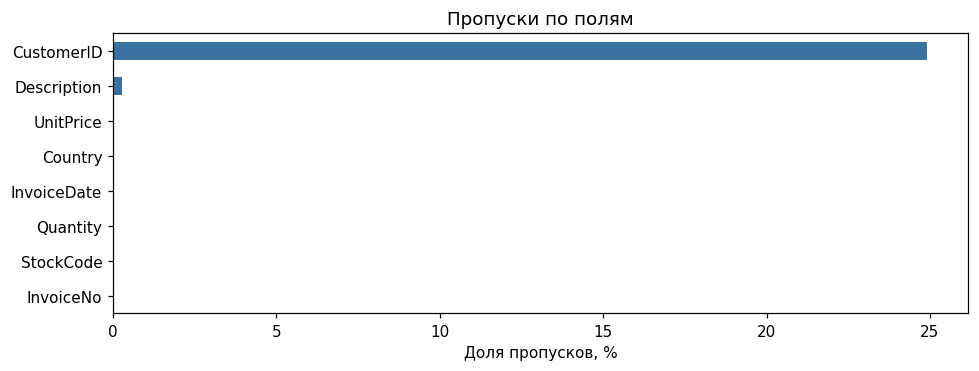

Без клиента: 135,080 строк (24.93%).
Без описания: 1,454 строк.
На странице UCI указано отсутствие пропусков; для расчётов используем фактический профиль CSV.


In [3]:
missing = pd.DataFrame({'missing_rows':df[RAW_COLS].isna().sum()})
missing['missing_pct'] = missing.missing_rows / len(df) * 100
display(missing)
display(pd.crosstab(df.CustomerID.isna().rename('CustomerID_missing'),
                    df.Description.isna().rename('Description_missing'), margins=True))
missing_group = df.assign(customer_missing=df.CustomerID.isna()).groupby('customer_missing').agg(
    rows=('InvoiceNo','size'), invoices=('InvoiceNo','nunique'),
    signed_value_gbp=('TotalPrice','sum'), zero_price=('UnitPrice',lambda s:int(s.eq(0).sum())))
display(missing_group)
fig, ax = plt.subplots(figsize=(9,3.5))
missing.missing_pct.sort_values().plot.barh(ax=ax, color='#3972a1')
ax.set(xlabel='Доля пропусков, %', title='Пропуски по полям')
fig.tight_layout(); fig.savefig(FIGURE_DIR/'01_missing.png', dpi=150); plt.show()
print(f'Без клиента: {df.CustomerID.isna().sum():,} строк ({df.CustomerID.isna().mean():.2%}).')
print(f'Без описания: {df.Description.isna().sum():,} строк.')
print('На странице UCI указано отсутствие пропусков; для расчётов используем фактический профиль CSV.')

## 4. Дубликаты и зерно таблицы

Полный повтор всех восьми исходных полей — кандидат на дубликат. Два совпадения `InvoiceNo + StockCode` не доказывают дублирование: SKU может присутствовать в документе несколько раз, например с разными ценами. В данных нет ID строки документа, поэтому невозможно доказать, что полные совпадения — ошибка загрузки. Для ЛР принимаем удаление полных повторов и показываем альтернативу без удаления.

In [4]:
duplicate_raw = raw.duplicated(subset=RAW_COLS, keep='first')
# Повторы определяем по исходным восьми полям ДО нормализации.
clean = df.loc[~duplicate_raw].copy()
duplicate_all = raw.duplicated(subset=RAW_COLS, keep=False)
duplicate_groups = raw.loc[duplicate_all].groupby(RAW_COLS, dropna=False).size().rename('copies')
print(f'Лишних полных повторов: {duplicate_raw.sum():,} ({duplicate_raw.mean():.2%})')
print(f'Строк в группах повторов: {duplicate_all.sum():,}; групп: {len(duplicate_groups):,}')
print(f'После удаления: {len(clean):,} строк')
display(duplicate_groups.sort_values(ascending=False).head(10).reset_index())
repeated_sku = clean.groupby(['InvoiceNo','StockCode'], dropna=False).agg(
    rows=('Quantity','size'), price_variants=('UnitPrice','nunique'),
    description_variants=('Description','nunique'))
display(repeated_sku[repeated_sku.rows.gt(1)].sort_values('rows',ascending=False).head(10))
print(f'Повторных пар документ + SKU после полной дедупликации: {repeated_sku.rows.gt(1).sum():,}')
print('drop_duplicates([InvoiceNo, StockCode]) использовать нельзя: потеряются реальные позиции.')

Лишних полных повторов: 5,268 (0.97%)
Строк в группах повторов: 10,147; групп: 4,879
После удаления: 536,641 строк


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,copies
0,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923,United Kingdom,20
1,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,6/5/2011 11:37,2.95,16923,United Kingdom,12
2,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,10/26/2011 12:46,1.25,14102,United Kingdom,8
3,572344,M,Manual,48,10/24/2011 10:43,1.5,14607,United Kingdom,6
4,540524,21756,BATH BUILDING BLOCK WORD,1,1/9/2011 12:53,5.95,16735,United Kingdom,6
5,578289,23395,BELLE JARDINIERE CUSHION COVER,1,11/23/2011 14:07,3.75,17841,United Kingdom,6
6,541266,21754,HOME BUILDING BLOCK WORD,1,1/16/2011 16:25,5.95,15673,United Kingdom,6
7,538514,21756,BATH BUILDING BLOCK WORD,1,12/12/2010 14:27,5.95,15044,United Kingdom,6
8,541266,21755,LOVE BUILDING BLOCK WORD,1,1/16/2011 16:25,5.95,15673,United Kingdom,6
9,537224,70007,HI TEC ALPINE HAND WARMER,1,12/5/2010 16:24,1.65,13174,United Kingdom,5


,,rows,price_variants,description_variants
InvoiceNo,StockCode,,,
C544580,S,15,15,1
C544583,S,7,7,1
C553531,S,7,7,1
C558347,S,6,6,1
541266,21621,4,1,1
571046,22197,4,1,1
568188,84879,4,1,1
548813,M,4,4,1
562549,20829,4,1,1


Повторных пар документ + SKU после полной дедупликации: 5,199
drop_duplicates([InvoiceNo, StockCode]) использовать нельзя: потеряются реальные позиции.


## 5. Качество значений и типы операций

Отрицательное количество в `C`-документе трактуется как кредитная операция (отмена или возврат). У источника нет статуса доставки и ссылки на исходный заказ, поэтому эти причины не разделяются достоверно. Нулевые цены могут означать списание, подарок или служебную операцию. Отрицательная цена не считается обычной продажей. Проверяем знаки совместно с типом документа.

In [5]:
is_c = clean.InvoiceNo.str.upper().str.startswith('C',na=False)
quality = pd.Series({
    'Quantity < 0':int(clean.Quantity.lt(0).sum()),
    'Quantity = 0':int(clean.Quantity.eq(0).sum()),
    'UnitPrice < 0':int(clean.UnitPrice.lt(0).sum()),
    'UnitPrice = 0':int(clean.UnitPrice.eq(0).sum()),
    'C-документы, строки':int(is_c.sum()),
    'C-документы, уникальные ID':clean.loc[is_c,'InvoiceNo'].nunique(),
    'Отрицательное Quantity без C':int((clean.Quantity.lt(0)&~is_c).sum()),
    'C с неотрицательным Quantity':int((is_c&clean.Quantity.ge(0)).sum()),
    'Нетипичный InvoiceNo':int((~clean.InvoiceNo.str.fullmatch(r'C?[0-9]{6}',na=False)).sum()),
    'Нетипичный CustomerID':int((clean.CustomerID.notna()&~clean.CustomerID.str.fullmatch(r'[0-9]{5}',na=False)).sum())})
display(quality.to_frame('rows_or_ids'))
display(pd.crosstab(is_c.rename('is_C'), [clean.Quantity.gt(0).rename('positive_quantity'),
                                         clean.UnitPrice.gt(0).rename('positive_price')]))
display(clean[clean.UnitPrice.lt(0)][RAW_COLS])
display(clean[clean.UnitPrice.eq(0)][RAW_COLS].head(10))
display(clean[['Quantity','UnitPrice','TotalPrice']].describe(percentiles=[.01,.05,.5,.95,.99,.999]).T)
print('Нулевая цена не участвует в платных продажах. Ошибочные типы и A-документы исключаются из метрик.')

,rows_or_ids
Quantity < 0,10587
Quantity = 0,0
UnitPrice < 0,2
UnitPrice = 0,2510
"C-документы, строки",9251
"C-документы, уникальные ID",3836
Отрицательное Quantity без C,1336
C с неотрицательным Quantity,0
Нетипичный InvoiceNo,3
Нетипичный CustomerID,0


positive_quantity False       True         
positive_price    False True  False   True 
is_C                                       
False              1336     0  1176  524878
True                  0  9251     0       0

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,<NA>,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,<NA>,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,<NA>,56,2010-12-01 11:52:00,0.0,<NA>,United Kingdom
1970,536545,21134,<NA>,1,2010-12-01 14:32:00,0.0,<NA>,United Kingdom
1971,536546,22145,<NA>,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1972,536547,37509,<NA>,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1987,536549,85226A,<NA>,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
1988,536550,85044,<NA>,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
2024,536552,20950,<NA>,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
2025,536553,37461,<NA>,3,2010-12-01 14:35:00,0.0,<NA>,United Kingdom
2026,536554,84670,<NA>,23,2010-12-01 14:35:00,0.0,<NA>,United Kingdom
2406,536589,21777,<NA>,-10,2010-12-01 16:50:00,0.0,<NA>,United Kingdom


,count,mean,std,min,1%,5%,50%,95%,99%,99.9%,max
Quantity,536641.0,9.620029,219.130156,-80995.0,-2.0,1.0,3.0,30.0,100.0,480.0,80995.0
UnitPrice,536641.0,4.632656,97.233118,-11062.06,0.19,0.42,2.08,9.95,18.0,207.9088,38970.0
TotalPrice,536641.0,18.123861,380.656263,-168469.6,-6.624,0.84,9.87,59.4,180.368,830.0,168469.6


Нулевая цена не участвует в платных продажах. Ошибочные типы и A-документы исключаются из метрик.


## 6. Товарный справочник и специальные коды

Не группируем по `Description`: переименование одного товара создаст ложные товары. Не ограничиваем коды регулярным выражением из описания UCI: реальные артикулы содержат буквы и встречаются нестандартные товарные коды. Для товарного рейтинга исключаем явные услуги, денежные корректировки и ваучеры. Список является явным бизнес-допущением и должен быть подтверждён справочником бизнеса.

Из клиентской суммы доставка и прочие начисления по обычным документам не исключаются: чек означает сумму всех платных позиций документа. Это оценка суммы по документам, а не доказанный денежный платёж, прибыль или бухгалтерская выручка.

In [6]:
NON_GOODS = {'POST','DOT','C2','M','D','BANK CHARGES','AMAZONFEE','CRUK','B','S'}
def add_flags(frame):
    out = frame.copy()
    out['is_goods'] = (out.StockCode.notna() & ~out.StockCode.str.upper().isin(NON_GOODS)
                       & ~out.StockCode.str.lower().str.startswith('gift_',na=False))
    valid = (out.InvoiceDate.notna() & out.Quantity.notna() & out.UnitPrice_1e4.notna()
             & out.StockCode.notna() & out.UnitPrice_1e4.gt(0))
    out['is_sale'] = valid & out.InvoiceNo.str.fullmatch(r'[0-9]{6}',na=False) & out.Quantity.gt(0)
    out['is_credit'] = valid & out.InvoiceNo.str.fullmatch(r'C[0-9]{6}',na=False) & out.Quantity.lt(0)
    return out
clean = add_flags(clean)
raw_flags = add_flags(df)
special = clean[~clean.StockCode.str.fullmatch(r'[0-9]{5}[A-Za-z]{0,2}',na=False)].groupby('StockCode').agg(
    rows=('Quantity','size'), quantity=('Quantity','sum'), sample_description=('Description','first'))
display(special)
sku_names = clean.groupby('StockCode').Description.nunique(dropna=True)
print(f'SKU с несколькими описаниями: {sku_names.gt(1).sum():,} из {len(sku_names):,}')
display(sku_names.sort_values(ascending=False).head(10).to_frame('description_variants'))
display(clean[clean.StockCode.isin(sku_names.nlargest(3).index)]
        [['StockCode','Description']].drop_duplicates().head(25))
# Для подписи SKU выбираем самое частое непустое название среди продаж;
# при равенстве частот — название по алфавиту. Оно не влияет на агрегацию.
name_counts = (clean[clean.is_sale & clean.Description.notna()]
    .groupby(['StockCode','Description']).size().rename('name_count').reset_index())
catalog = (name_counts.sort_values(['StockCode','name_count','Description'],ascending=[True,False,True])
    .drop_duplicates('StockCode')[['StockCode','Description']])

,rows,quantity,sample_description
StockCode,,,
AMAZONFEE,34,-30,AMAZON FEE
B,3,3,Adjust bad debt
BANK CHARGES,37,-13,Bank Charges
C2,144,290,CARRIAGE
CRUK,16,-16,CRUK Commission
D,77,-1194,Discount
DCGS0003,5,-3,BOXED GLASS ASHTRAY
DCGS0004,1,1,HAYNES CAMPER SHOULDER BAG
DCGS0055,1,-1,<NA>


SKU с несколькими описаниями: 647 из 4,070


,description_variants
StockCode,
20713,8
23084,7
21830,6
85175,6
21181,5
72807A,5
23131,5
23343,5
85172,5


,StockCode,Description
522,20713,JUMBO BAG OWLS
2599,21830,ASSORTED CREEPY CRAWLIES
136272,20713,<NA>
151035,21830,"MERCHANT CHANDLER CREDIT ERROR, STO"
183218,23084,RABBIT NIGHT LIGHT
263884,20713,wrongly marked. 23343 in box
275365,23084,<NA>
323461,21830,sold as 1
323462,21830,?
332824,23084,temp adjustment


## 7. Согласованность документов и клиентов

Заказ считают по уникальному `InvoiceNo`, а не по числу строк. Проверяем, встречается ли один документ у нескольких клиентов или стран. Разные временные метки внутри документа выводим отдельно: они не создают новый заказ. Связь клиента со страной не обязательно постоянна и не является основанием удалять клиента.

In [7]:
invoice_profile = clean.groupby('InvoiceNo').agg(
    rows=('StockCode','size'), customers=('CustomerID','nunique'),
    countries=('Country','nunique'), timestamps=('InvoiceDate','nunique'),
    customer_null_rows=('CustomerID',lambda s:int(s.isna().sum())))
display(invoice_profile[['rows','customers','countries','timestamps']].describe().T)
print('Документов с несколькими известными клиентами:',int(invoice_profile.customers.gt(1).sum()))
print('Документов с несколькими странами:',int(invoice_profile.countries.gt(1).sum()))
print('Документов с несколькими временными метками:',int(invoice_profile.timestamps.gt(1).sum()))
mixed_customer = invoice_profile.customer_null_rows.gt(0)&invoice_profile.customers.gt(0)
print('Документов одновременно с известным и неизвестным клиентом:',int(mixed_customer.sum()))
display(invoice_profile[invoice_profile.timestamps.gt(1)].head(10))
customer_countries = clean.groupby('CustomerID').Country.nunique()
print('Клиентов с несколькими странами:',int(customer_countries.gt(1).sum()))
assert not invoice_profile.customers.gt(1).any(), 'Нужно решить конфликт InvoiceNo → CustomerID'
print('Функциональная зависимость InvoiceNo → известный CustomerID подтверждена на этом CSV.')

,count,mean,std,min,25%,50%,75%,max
rows,25900.0,20.719730,42.793088,1.0,2.0,10.0,23.0,1114.0
customers,25900.0,0.856757,0.350327,0.0,1.0,1.0,1.0,1.0
countries,25900.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
timestamps,25900.0,1.001660,0.040713,1.0,1.0,1.0,1.0,2.0


Документов с несколькими известными клиентами: 0
Документов с несколькими странами: 0
Документов с несколькими временными метками: 43
Документов одновременно с известным и неизвестным клиентом: 0


,rows,customers,countries,timestamps,customer_null_rows
InvoiceNo,,,,,
536591,40,1,1,2,0
540185,29,1,1,2,0
541596,103,1,1,2,0
541631,72,1,1,2,0
541809,91,0,1,2,91
541816,73,1,1,2,0
541849,45,1,1,2,0
542217,18,1,1,2,0
542806,39,1,1,2,0


Клиентов с несколькими странами: 8
Функциональная зависимость InvoiceNo → известный CustomerID подтверждена на этом CSV.


## 8. Воронка отбора и определения метрик

Основные расчёты:

1. Полная дедупликация по восьми исходным полям, затем нормализация и проверка типов.
2. **Продажа**: `InvoiceNo` состоит из 6 цифр, `Quantity > 0`, `UnitPrice > 0`, дата и SKU заполнены и типы валидны.
3. **Кредитная операция**: `C` + 6 цифр, `Quantity < 0`, `UnitPrice > 0`, остальные проверки те же.
4. **Топ-5 gross**: сумма `Quantity` только по продажам товарных позиций, все страны, включая строки без клиента.
5. **Клиенты gross**: только продажи с известным клиентом; сумма всех позиций, включая доставку и ручные начисления.
6. Число заказов = число уникальных продажных `InvoiceNo`; сумма = сумма `Quantity × UnitPrice`; средний чек = сумма / число заказов.

Дополнительно: **net** = продажи + подписанные суммы кредитных операций. Для товаров это `sold_units − returned_units`. Для клиента `net_spent = gross_spent + credit_amount`. `net_per_sales_order` использует число исходных продажных документов как знаменатель. Это показатель net-суммы периода на продажный заказ, а не чек сопоставленных и окончательно оплаченных заказов.

Все 4 372 известных ID исходника сохраняются в клиентской выгрузке, даже если у ID нет допустимых продаж: `orders_count=0`, `total_spent=0`, `average_order_value=NULL`. Число таких клиентов показывается ниже. Отсутствующий ID в выгрузку клиентов не включается.

In [8]:
sales = clean[clean.is_sale].copy()
credits = clean[clean.is_credit].copy()
identified_sales = sales[sales.CustomerID.notna()].copy()
flow = pd.DataFrame([
    ('Исходный CSV',len(raw)),
    ('После удаления полных повторов',len(clean)),
    ('Допустимые положительные продажи',len(sales)),
    ('Товарные позиции продаж для топ-5',int(sales.is_goods.sum())),
    ('Продажи с известным клиентом',len(identified_sales)),
    ('Допустимые кредитные позиции',len(credits)),
    ('Прочие позиции после дедупликации',len(clean)-len(sales)-len(credits))
],columns=['stage','rows'])
display(flow)
print(f'Период: {clean.InvoiceDate.min()} — {clean.InvoiceDate.max()}')
print(f'Продажные документы: {sales.InvoiceNo.nunique():,}; из них с клиентом: {identified_sales.InvoiceNo.nunique():,}')
print(f'Продажи без клиента: {len(sales)-len(identified_sales):,} строк, '
      f'{sales.loc[sales.CustomerID.isna(),"TotalPrice_1e4"].sum()/10000:,.2f} GBP')
print(f'Доля валовой суммы продаж, которую нельзя отнести клиенту: '
      f'{sales.loc[sales.CustomerID.isna(),"TotalPrice_1e4"].sum()/sales.TotalPrice_1e4.sum():.2%}')

,stage,rows
0,Исходный CSV,541909
1,После удаления полных повторов,536641
2,Допустимые положительные продажи,524877
3,Товарные позиции продаж для топ-5,522540
4,Продажи с известным клиентом,392692
5,Допустимые кредитные позиции,9251
6,Прочие позиции после дедупликации,2513


Период: 2010-12-01 08:26:00 — 2011-12-09 12:50:00
Продажные документы: 19,959; из них с клиентом: 18,532
Продажи без клиента: 132,185 строк, 1,743,839.85 GBP
Доля валовой суммы продаж, которую нельзя отнести клиенту: 16.40%


## 9. Выбросы и отменённые крупные продажи

Компания работает в том числе с оптовиками. Большое количество или чек не доказывают ошибку. Выбросы по IQR и верхним квантилям исследуются, но автоматически не отрезаются: иначе изменятся требуемые бизнес-суммы. Для крайних продаж ищем возможную компенсирующую кредитную операцию того же клиента и SKU с тем же количеством и ценой. Такое совпадение — диагностическая связь, без исходного ID заказа это не подтверждённый join для бухгалтерского расчёта.

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,168469.6
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,77183.6
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00,0.21,12901,United Kingdom,1008.0
206121,554868,22197,SMALL POPCORN HOLDER,4300,2011-05-27 10:52:00,0.72,13135,United Kingdom,3096.0
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,2011-02-22 10:43:00,0.82,18087,United Kingdom,3202.92
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,2011-07-19 17:04:00,0.06,14609,United Kingdom,191.16
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.1,15749,United Kingdom,6539.4
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00,2.1,15749,United Kingdom,6539.4
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,2011-11-02 11:24:00,0.32,16308,United Kingdom,960.0
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,2010-12-02 17:38:00,0.18,16754,United Kingdom,518.4


Верхняя граница IQR Quantity: 26; выше неё 27,111 строк.
99-й перцентиль Quantity: 100; выше него 4,847 строк.


,sale_invoice,credit_invoice,StockCode,CustomerID,sale_units,minutes_to_credit
0,581483,C581484,23843,16446,80995,12.0
1,541431,C541433,23166,12346,74215,16.0


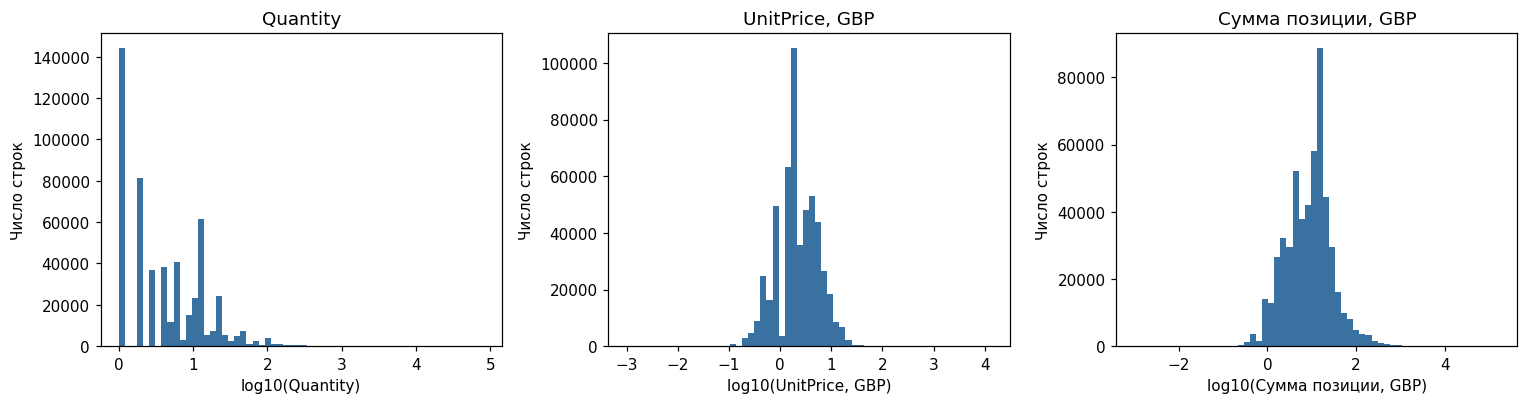

Две крайние продажи компенсируются кредитными документами через минуты. Gross-рейтинг чувствителен к ним.


In [9]:
extreme_sales = sales.nlargest(10,'Quantity')[RAW_COLS+['TotalPrice']]
display(extreme_sales)
q1,q3 = sales.Quantity.quantile([.25,.75]).astype(float)
iqr_limit = q3+1.5*(q3-q1)
print(f'Верхняя граница IQR Quantity: {iqr_limit:g}; выше неё {sales.Quantity.gt(iqr_limit).sum():,} строк.')
p99 = float(sales.Quantity.quantile(.99))
print(f'99-й перцентиль Quantity: {p99:g}; выше него {sales.Quantity.gt(p99).sum():,} строк.')
pair_candidates = []
for row in sales.nlargest(5,'Quantity').itertuples():
    matched = credits[(credits.CustomerID.eq(row.CustomerID)) & credits.StockCode.eq(row.StockCode)
                      & credits.Quantity.eq(-row.Quantity) & credits.UnitPrice_1e4.eq(row.UnitPrice_1e4)
                      & credits.InvoiceDate.ge(row.InvoiceDate)]
    for cr in matched.itertuples():
        pair_candidates.append({'sale_invoice':row.InvoiceNo,'credit_invoice':cr.InvoiceNo,
                                'StockCode':row.StockCode,'CustomerID':row.CustomerID,
                                'sale_units':int(row.Quantity),'minutes_to_credit':
                                (cr.InvoiceDate-row.InvoiceDate).total_seconds()/60})
display(pd.DataFrame(pair_candidates))
fig, axes = plt.subplots(1,3,figsize=(14,3.8))
for ax,col,label in zip(axes,['Quantity','UnitPrice','TotalPrice'],['Quantity','UnitPrice, GBP','Сумма позиции, GBP']):
    values = np.asarray(sales[col],dtype=float)
    ax.hist(np.log10(values),bins=60,color='#3972a1')
    ax.set(xlabel=f'log10({label})',ylabel='Число строк',title=label)
fig.tight_layout(); fig.savefig(FIGURE_DIR/'02_distributions.png',dpi=150); plt.show()
print('Две крайние продажи компенсируются кредитными документами через минуты. Gross-рейтинг чувствителен к ним.')

## 10. Динамика, география и структура спроса

Изучаем продажи и кредиты отдельно, не смешивая со списаниями по нулевой цене. Декабрь 2010 представлен с первого числа; декабрь 2011 заканчивается 9 декабря и не сопоставим с полным месяцем. Рост/сезонность нельзя заключать по неполному декабрю или одному году наблюдений. Часовой пояс в источнике не задан: даты считаются локальным временем источника без конвертации в текущий часовой пояс.

,orders,units,customers,gross_value_gbp,credit_value_gbp,net_value_gbp,complete_calendar_month
month,,,,,,,
2010-12,1559,358019,885,821452.73,-74729.12,746723.61,True
2011-01,1086,387099,741,689811.61,-131363.05,558448.56,True
2011-02,1100,282934,758,522545.56,-25519.15,497026.41,True
2011-03,1454,376599,974,716215.26,-34201.28,682013.98,True
2011-04,1246,307953,856,536968.491,-44600.65,492367.841,True
2011-05,1681,395001,1056,769296.61,-47202.51,722094.1,True
2011-06,1533,388511,991,760547.01,-70569.78,689977.23,True
2011-07,1475,399693,949,718076.121,-37919.13,680156.991,True
2011-08,1360,421019,935,746779.32,-54330.8,692448.52,True


,rows,orders,customers,units,gross_value_gbp,gross_share_pct
Country,,,,,,
United Kingdom,479984,18018,3920,4646905,8990682.034,84.570039
Netherlands,2359,94,9,200361,285446.34,2.685025
EIRE,7879,288,3,147007,283140.52,2.663336
Germany,9025,457,94,119154,228678.4,2.151043
France,8392,392,87,112060,209625.37,1.971822
Australia,1181,57,9,83891,138453.81,1.302353
Spain,2479,90,30,27933,61558.56,0.579045
Switzerland,1958,54,21,30617,57067.6,0.536801
Belgium,2031,98,25,23237,41196.34,0.38751


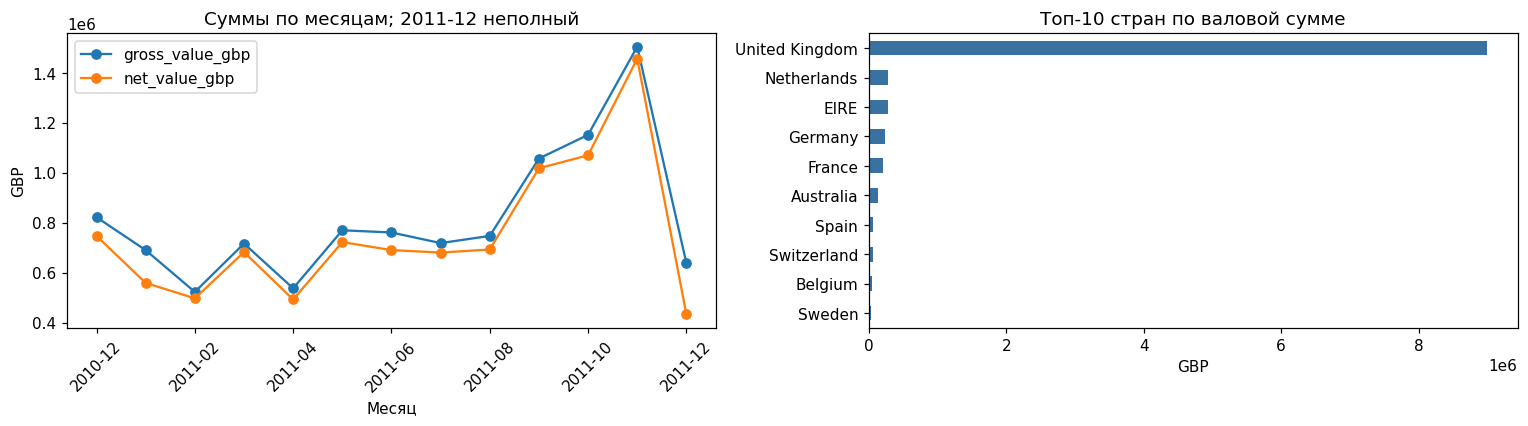

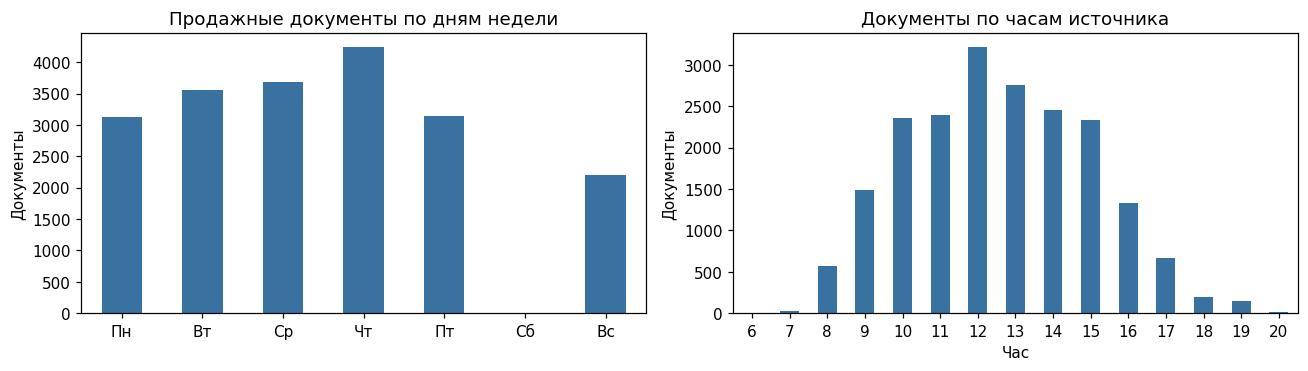

Доля United Kingdom в gross: 84.57%
Документ с несколькими временными метками может участвовать в двух часах; почасовые counts не аддитивны.


In [10]:
monthly = sales.assign(month=sales.InvoiceDate.dt.to_period('M').astype(str)).groupby('month').agg(
    gross_value_1e4=('TotalPrice_1e4','sum'), orders=('InvoiceNo','nunique'),
    units=('Quantity','sum'), customers=('CustomerID','nunique'))
credit_month = credits.assign(month=credits.InvoiceDate.dt.to_period('M').astype(str)).groupby('month').TotalPrice_1e4.sum()
monthly['credit_value_1e4'] = credit_month.reindex(monthly.index,fill_value=0)
monthly['gross_value_gbp'] = monthly.gross_value_1e4/10000
monthly['credit_value_gbp'] = monthly.credit_value_1e4/10000
monthly['net_value_gbp'] = monthly.gross_value_gbp+monthly.credit_value_gbp
monthly['complete_calendar_month'] = ~monthly.index.isin(['2011-12'])
display(monthly.drop(columns=['gross_value_1e4','credit_value_1e4']))
country = sales.groupby('Country').agg(rows=('StockCode','size'), orders=('InvoiceNo','nunique'),
    customers=('CustomerID','nunique'), units=('Quantity','sum'), gross_value_1e4=('TotalPrice_1e4','sum'))
country['gross_value_gbp']=country.gross_value_1e4/10000
country['gross_share_pct']=country.gross_value_1e4/country.gross_value_1e4.sum()*100
display(country.sort_values('gross_value_1e4',ascending=False).head(10).drop(columns='gross_value_1e4'))
fig,axes = plt.subplots(1,2,figsize=(14,4))
monthly[['gross_value_gbp','net_value_gbp']].plot(ax=axes[0],marker='o')
axes[0].set(title='Суммы по месяцам; 2011-12 неполный',xlabel='Месяц',ylabel='GBP')
axes[0].tick_params(axis='x',rotation=45)
country.gross_value_gbp.nlargest(10).sort_values().plot.barh(ax=axes[1],color='#3972a1')
axes[1].set(title='Топ-10 стран по валовой сумме',xlabel='GBP',ylabel='')
fig.tight_layout(); fig.savefig(FIGURE_DIR/'03_time_country.png',dpi=150); plt.show()
weekday = sales.assign(weekday=sales.InvoiceDate.dt.dayofweek).groupby('weekday').agg(
    gross_value_1e4=('TotalPrice_1e4','sum'),orders=('InvoiceNo','nunique'))
weekday = weekday.reindex(range(7),fill_value=0)
weekday.index = ['Пн','Вт','Ср','Чт','Пт','Сб','Вс']
hours = sales.assign(hour=sales.InvoiceDate.dt.hour).groupby('hour').InvoiceNo.nunique()
fig,axes = plt.subplots(1,2,figsize=(12,3.5))
weekday.orders.plot.bar(ax=axes[0],color='#3972a1',rot=0)
axes[0].set(title='Продажные документы по дням недели',ylabel='Документы',xlabel='')
hours.plot.bar(ax=axes[1],color='#3972a1',rot=0)
axes[1].set(title='Документы по часам источника',ylabel='Документы',xlabel='Час')
fig.tight_layout(); fig.savefig(FIGURE_DIR/'04_calendar.png',dpi=150); plt.show()
print(f'Доля United Kingdom в gross: {country.loc["United Kingdom","gross_share_pct"]:.2f}%')
print('Документ с несколькими временными метками может участвовать в двух часах; почасовые counts не аддитивны.')

## 11. Задание 1: топ-5 товаров

Ключ группировки — `StockCode`. Популярность в задании означает количество единиц, не число строк, заказов или выручку. При равенстве количества используем `StockCode ASC`, чтобы топ-5 был воспроизводим. Название присоединяется после агрегации. Для сравнения возвращаем также количество кредитованных единиц и net-рейтинг.

,StockCode,Description,total_quantity,orders_with_product,gross_value_gbp
2465,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,1,168469.6
2020,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,247,81700.92
1109,22197,POPCORN HOLDER,56898,1392,51334.47
2909,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,535,13814.01
3387,85099B,JUMBO BAG RED RETROSPOT,48371,2089,94159.81


,StockCode,Description,total_quantity,returned_units,net_quantity
1112,22197,POPCORN HOLDER,56898,471,56427
2916,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,1200,53751
3401,85099B,JUMBO BAG RED RETROSPOT,48371,1115,47256
3202,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,80,36282
440,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,380,36016


Рейтинг gross включает временно зарегистрированные продажи, даже если потом была отмена.
Net лучше отражает количество за вычетом кредитных документов периода; это не число доставленных товаров.


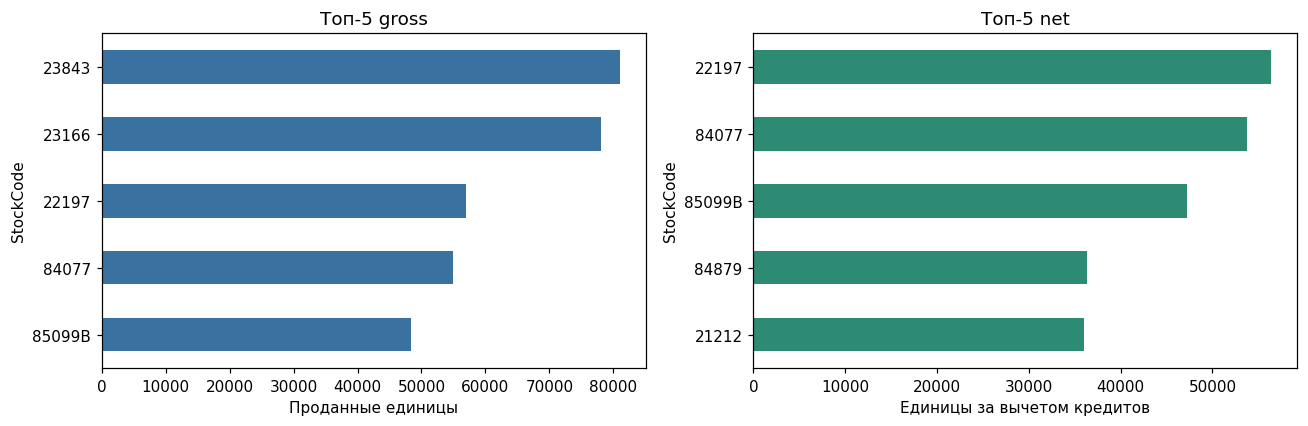

In [11]:
gross_products = sales[sales.is_goods].groupby('StockCode',as_index=False).agg(
    total_quantity=('Quantity','sum'), orders_with_product=('InvoiceNo','nunique'),
    gross_value_1e4=('TotalPrice_1e4','sum'))
gross_products = gross_products.merge(catalog,on='StockCode',how='left',validate='one_to_one')
gross_products = gross_products.sort_values(['total_quantity','StockCode'],ascending=[False,True])
gross_products['gross_value_gbp'] = gross_products.gross_value_1e4/10000
top5 = gross_products[['StockCode','Description','total_quantity','orders_with_product','gross_value_gbp']].head(5).copy()
display(top5)
returned_units = (-credits[credits.is_goods].groupby('StockCode').Quantity.sum()).rename('returned_units')
net_products = (gross_products.set_index('StockCode')[['Description','total_quantity']]
                .join(returned_units,how='outer'))
net_products[['total_quantity','returned_units']] = net_products[['total_quantity','returned_units']].fillna(0).astype('Int64')
net_products['net_quantity'] = net_products.total_quantity-net_products.returned_units
net_products = net_products.reset_index().sort_values(['net_quantity','StockCode'],ascending=[False,True])
top5_net = net_products.head(5).copy()
display(top5_net)
print('Рейтинг gross включает временно зарегистрированные продажи, даже если потом была отмена.')
print('Net лучше отражает количество за вычетом кредитных документов периода; это не число доставленных товаров.')
fig,axes=plt.subplots(1,2,figsize=(12,4))
top5.set_index('StockCode').total_quantity.sort_values().plot.barh(ax=axes[0],color='#3972a1')
top5_net.set_index('StockCode').net_quantity.sort_values().plot.barh(ax=axes[1],color='#2d8b73')
axes[0].set(title='Топ-5 gross',xlabel='Проданные единицы',ylabel='StockCode')
axes[1].set(title='Топ-5 net',xlabel='Единицы за вычетом кредитов',ylabel='StockCode')
fig.tight_layout(); fig.savefig(FIGURE_DIR/'05_top5.png',dpi=150); plt.show()

## 12. Задание 2: заказы, сумма и средний чек каждого клиента

Сначала суммируем строки в заказ, затем агрегируем заказы по клиенту. Это предотвращает ошибку `AVG(TotalPrice)` на уровне позиции. Возвратный документ не увеличивает число продажных заказов. Бесплатный документ без платных строк не считается платным заказом; если бесплатная позиция внутри платного заказа, этот заказ уже учтён по другим позициям.

До агрегации суммы хранятся с точностью 4 знака. В CSV деньги округляются до 2 знаков методом HALF_UP. Средний чек вычисляется из точной суммы, а не из уже округлённых чеков. Технический файл `orders.csv` хранит также точную сумму заказа для сверки.

In [12]:
orders = identified_sales.groupby(['CustomerID','InvoiceNo'],as_index=False).agg(
    order_total_1e4=('TotalPrice_1e4','sum'), line_count=('StockCode','size'),
    order_date=('InvoiceDate','min'))
gross_customer = orders.groupby('CustomerID',as_index=False).agg(
    orders_count=('InvoiceNo','nunique'), total_spent_1e4=('order_total_1e4','sum'))
customer_ids = pd.DataFrame({'CustomerID':sorted(clean.CustomerID.dropna().unique())})
customer_work = customer_ids.merge(gross_customer,on='CustomerID',how='left',validate='one_to_one')
customer_work[['orders_count','total_spent_1e4']] = customer_work[['orders_count','total_spent_1e4']].fillna(0).astype('Int64')
def money_2dp(amount_1e4, divisor=1):
    if pd.isna(divisor) or divisor == 0 or pd.isna(amount_1e4):
        return None
    return (Decimal(int(amount_1e4))/Decimal(10000)/Decimal(int(divisor))).quantize(Decimal('0.01'),rounding=ROUND_HALF_UP)
customer_metrics = customer_work[['CustomerID','orders_count']].copy()
customer_metrics['total_spent'] = customer_work.total_spent_1e4.map(money_2dp)
customer_metrics['average_order_value'] = [money_2dp(t,n) for t,n in
    zip(customer_work.total_spent_1e4,customer_work.orders_count)]
display(customer_metrics.head(12))
print('Всего известных клиентов:',len(customer_metrics))
print('С допустимыми продажами:',int(customer_metrics.orders_count.gt(0).sum()))
print('Без допустимых продаж:',int(customer_metrics.orders_count.eq(0).sum()))
display(customer_metrics[customer_metrics.orders_count.eq(0)].head(8))
credits_customer = credits[credits.CustomerID.notna()].groupby('CustomerID').agg(
    credit_amount_1e4=('TotalPrice_1e4','sum'), credit_documents=('InvoiceNo','nunique'))
net_work = customer_work.set_index('CustomerID').join(credits_customer,how='left')
net_work[['credit_amount_1e4','credit_documents']] = net_work[['credit_amount_1e4','credit_documents']].fillna(0).astype('Int64')
net_work['net_spent_1e4'] = net_work.total_spent_1e4+net_work.credit_amount_1e4
customer_net = net_work[['orders_count','credit_documents']].reset_index()
customer_net['gross_spent'] = net_work.total_spent_1e4.map(money_2dp).to_list()
customer_net['credit_amount'] = net_work.credit_amount_1e4.map(money_2dp).to_list()
customer_net['net_spent'] = net_work.net_spent_1e4.map(money_2dp).to_list()
customer_net['net_per_sales_order'] = [money_2dp(t,n) for t,n in zip(net_work.net_spent_1e4,net_work.orders_count)]
display(customer_net[customer_net.CustomerID.isin(['12346','16446'])])
print('Отрицательная net-сумма возможна: возврат может относиться к продаже вне периода наблюдения.')

,CustomerID,orders_count,total_spent,average_order_value
0,12346,1,77183.60,77183.60
1,12347,7,4310.00,615.71
2,12348,4,1797.24,449.31
3,12349,1,1757.55,1757.55
4,12350,1,334.40,334.40
5,12352,8,2506.04,313.26
6,12353,1,89.00,89.00
7,12354,1,1079.40,1079.40
8,12355,1,459.40,459.40
9,12356,3,2811.43,937.14


Всего известных клиентов: 4372
С допустимыми продажами: 4338
Без допустимых продаж: 34


,CustomerID,orders_count,total_spent,average_order_value
125,12503,0,0.00,None
127,12505,0,0.00,None
212,12605,0,0.00,None
264,12666,0,0.00,None
415,12870,0,0.00,None
467,12943,0,0.00,None
619,13154,0,0.00,None
692,13256,0,0.00,None


,CustomerID,orders_count,credit_documents,gross_spent,credit_amount,net_spent,net_per_sales_order
0,12346,1,1,77183.60,-77183.60,0.00,0.00
3033,16446,2,1,168472.50,-168469.60,2.90,1.45


Отрицательная net-сумма возможна: возврат может относиться к продаже вне периода наблюдения.


## 13. Клиентская структура и концентрация продаж

Показываем распределение числа заказов, медианный чек и концентрацию суммы у крупнейших клиентов. Среднее арифметическое средних чеков клиентов и средний чек компании — разные метрики. Для компании знаменатель — суммарное число заказов, то есть клиентские чеки взвешиваются числом заказов.

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
orders_count,4338.0,4.272015,7.697998,1.0,1.0,2.0,5.0,9.0,13.0,30.0,209.0
avg_order_gbp,4338.0,417.645735,1796.511343,3.45,177.867083,291.94,428.280625,659.735167,936.332,2031.1612,84236.25


Топ 1% клиентов (44 ID): 32.06% gross-суммы.
Топ 5% клиентов (217 ID): 50.46% gross-суммы.
Топ 10% клиентов (434 ID): 61.45% gross-суммы.
Доля клиентов с >1 платным заказом: 65.58%
Средний чек компании по известным клиентам: 479.56 GBP
Медианный заказ: 302.57 GBP


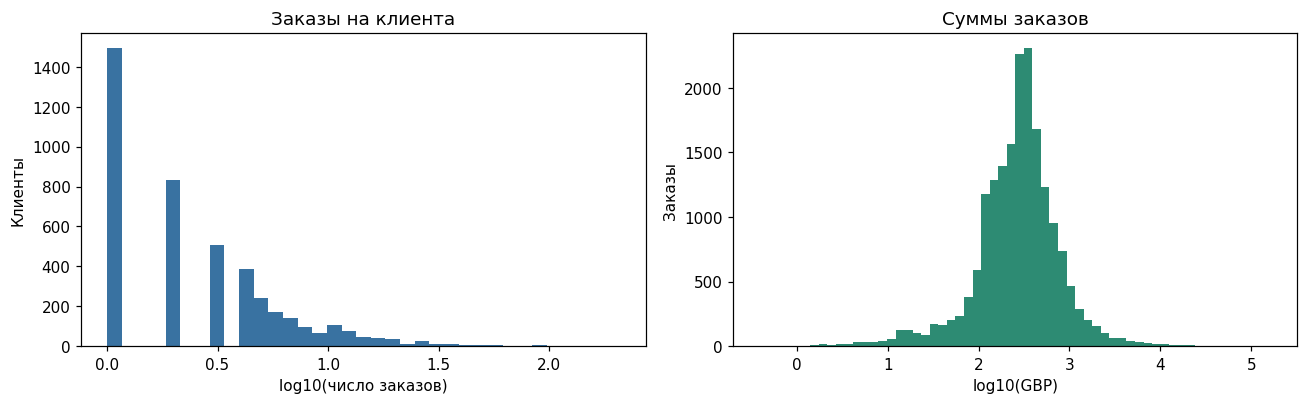

In [13]:
active = customer_work[customer_work.orders_count.gt(0)].copy()
active['avg_order_gbp'] = active.total_spent_1e4/10000/active.orders_count
display(active[['orders_count','avg_order_gbp']].describe(percentiles=[.25,.5,.75,.9,.95,.99]).T)
repeat_share = active.orders_count.gt(1).mean()
largest = active.sort_values('total_spent_1e4',ascending=False)
for share in [.01,.05,.10]:
    n=max(1,int(np.ceil(len(largest)*share)))
    print(f'Топ {share:.0%} клиентов ({n} ID): {largest.head(n).total_spent_1e4.sum()/largest.total_spent_1e4.sum():.2%} gross-суммы.')
print(f'Доля клиентов с >1 платным заказом: {repeat_share:.2%}')
print(f'Средний чек компании по известным клиентам: {identified_sales.TotalPrice_1e4.sum()/10000/len(orders):,.2f} GBP')
print(f'Медианный заказ: {orders.order_total_1e4.median()/10000:,.2f} GBP')
fig,axes = plt.subplots(1,2,figsize=(12,3.8))
axes[0].hist(np.log10(active.orders_count.astype(float)),bins=35,color='#3972a1')
axes[0].set(title='Заказы на клиента',xlabel='log10(число заказов)',ylabel='Клиенты')
axes[1].hist(np.log10(orders.order_total_1e4.astype(float)/10000),bins=60,color='#2d8b73')
axes[1].set(title='Суммы заказов',xlabel='log10(GBP)',ylabel='Заказы')
fig.tight_layout(); fig.savefig(FIGURE_DIR/'06_customers.png',dpi=150); plt.show()

## 14. Чувствительность к правилам очистки

Сравниваем отсутствие дедупликации, принятую очистку, механическое ограничение выбросов и товарную сумму без услуг. Вариант «обрезать 99-й перцентиль» приводится как диагностика потерь, не используется в итоговых выгрузках. Отдельно видно, что исключение всех строк без клиента ошибочно уменьшит общий объём продаж и может изменить товарный рейтинг.

In [14]:
def scenario_summary(label,frame):
    s=frame[frame.is_sale]
    return {'scenario':label,'sales_rows':len(s),'orders':s.InvoiceNo.nunique(),
            'known_customers':s.CustomerID.nunique(),'units':int(s.Quantity.sum()),
            'gross_gbp':float(s.TotalPrice_1e4.sum()/10000),
            'known_customer_gross_gbp':float(s.loc[s.CustomerID.notna(),'TotalPrice_1e4'].sum()/10000),
            'top5_goods':', '.join(s[s.is_goods].groupby('StockCode').Quantity.sum().reset_index()
                .sort_values(['Quantity','StockCode'],ascending=[False,True]).head(5).StockCode)}
sensitivity=pd.DataFrame([
    scenario_summary('Без удаления полных повторов',raw_flags),
    scenario_summary('Основной gross после дедупликации',clean),
    scenario_summary('Только известные клиенты',clean[clean.CustomerID.notna()]),
    scenario_summary('Только товары, без услуг и ваучеров',clean[clean.is_goods]),
    scenario_summary('Quantity <= p99 (диагностика)',clean[~clean.is_sale|clean.Quantity.le(p99)])
])
display(sensitivity)
dedup_delta = sensitivity.loc[0,'gross_gbp']-sensitivity.loc[1,'gross_gbp']
print(f'Дедупликация уменьшила gross-сумму на {dedup_delta:,.2f} GBP.')
print('Исключение крайних количеств меняет реальный результат: в финальном расчёте выбросы сохранены.')

,scenario,sales_rows,orders,known_customers,units,gross_gbp,known_customer_gross_gbp,top5_goods
0,Без удаления полных повторов,530103,19959,4338,5588375,1.065562e+07,8911407.904,"23843, 23166, 22197, 84077, 85099B"
1,Основной gross после дедупликации,524877,19959,4338,5572419,1.063105e+07,8887208.894,"23843, 23166, 22197, 84077, 85099B"
2,Только известные клиенты,392692,18532,4338,5152002,8.887209e+06,8887208.894,"23843, 23166, 84077, 22197, 85099B"
3,"Только товары, без услуг и ваучеров",522540,19773,4334,5561387,1.024722e+07,8737227.643,"23843, 23166, 22197, 84077, 85099B"
4,Quantity <= p99 (диагностика),520030,19541,4303,4154805,8.687694e+06,7069268.394,"85099B, 22197, 85123A, 84879, 84077"


Дедупликация уменьшила gross-сумму на 24,573.74 GBP.
Исключение крайних количеств меняет реальный результат: в финальном расчёте выбросы сохранены.


## 15. Контрольные сверки и выгрузки

Проверяем ключи, отсутствие отрицательных gross-метрик, равенство суммы строк, заказов и клиентов до округления, знаменатель среднего чека и порядок top-5. Сверки на целых десятитысячных GBP точные. Сумма округлённых клиентских сумм может отличаться от общей округлённой суммы из-за субпенсовых цен; это не ошибка агрегации.

In [15]:
assert len(raw) == len(clean)+int(duplicate_raw.sum())
assert len(clean) == len(sales)+len(credits)+len(clean[~clean.is_sale & ~clean.is_credit])
assert customer_metrics.CustomerID.is_unique and customer_metrics.CustomerID.notna().all()
assert len(customer_metrics) == clean.CustomerID.nunique()
assert orders[['CustomerID','InvoiceNo']].duplicated().sum() == 0
assert int(customer_work.orders_count.sum()) == len(orders) == identified_sales.InvoiceNo.nunique()
assert int(orders.order_total_1e4.sum()) == int(identified_sales.TotalPrice_1e4.sum())
assert int(customer_work.total_spent_1e4.sum()) == int(identified_sales.TotalPrice_1e4.sum())
assert customer_work.orders_count.ge(0).all() and customer_work.total_spent_1e4.ge(0).all()
assert (customer_metrics.average_order_value.isna().to_numpy() == customer_metrics.orders_count.eq(0).to_numpy()).all()
assert gross_products.StockCode.is_unique and len(top5)==5
assert top5.total_quantity.is_monotonic_decreasing
assert int(gross_products.total_quantity.sum()) == int(sales.loc[sales.is_goods,'Quantity'].sum())
assert int(net_work.net_spent_1e4.sum()) == int(identified_sales.TotalPrice_1e4.sum()+
        credits.loc[credits.CustomerID.notna(),'TotalPrice_1e4'].sum())
# Независимая сверка среднего чека выбранного клиента по списку его документов.
sample_id = active.sort_values(['orders_count','CustomerID'],ascending=[False,True]).iloc[0].CustomerID
sample_lines = identified_sales[identified_sales.CustomerID.eq(sample_id)]
sample_orders = sample_lines.groupby('InvoiceNo').TotalPrice_1e4.sum()
sample_metric = customer_metrics.set_index('CustomerID').loc[sample_id]
assert sample_metric.orders_count == len(sample_orders)
assert sample_metric.average_order_value == money_2dp(sample_orders.sum(),len(sample_orders))
print(f'Сверки пройдены. Проверочный клиент {sample_id}: {len(sample_orders)} заказов.')

customer_metrics.to_csv(OUTPUT_DIR/'customer_metrics.csv',index=False,encoding='utf-8-sig',na_rep='')
customer_net.to_csv(OUTPUT_DIR/'customer_metrics_net.csv',index=False,encoding='utf-8-sig',na_rep='')
top5.to_csv(OUTPUT_DIR/'top5_products.csv',index=False,encoding='utf-8-sig',float_format='%.4f')
top5_net.to_csv(OUTPUT_DIR/'top5_products_net.csv',index=False,encoding='utf-8-sig')
orders_export=orders.copy()
orders_export['order_total_exact']=orders_export.order_total_1e4.map(lambda x:format(Decimal(int(x))/10000,'.4f'))
orders_export['order_total']=orders_export.order_total_1e4.map(money_2dp)
orders_export.to_csv(OUTPUT_DIR/'orders.csv',index=False,encoding='utf-8-sig')
missing.to_csv(OUTPUT_DIR/'missing_values.csv',encoding='utf-8-sig')
flow.to_csv(OUTPUT_DIR/'filter_flow.csv',index=False,encoding='utf-8-sig')
sensitivity.to_csv(OUTPUT_DIR/'sensitivity.csv',index=False,encoding='utf-8-sig')
monthly.drop(columns=['gross_value_1e4','credit_value_1e4']).to_csv(OUTPUT_DIR/'monthly_metrics.csv',encoding='utf-8-sig')
country.drop(columns='gross_value_1e4').sort_values('gross_value_gbp',ascending=False).to_csv(
    OUTPUT_DIR/'country_metrics.csv',encoding='utf-8-sig')
check_totals={
    'source_sha256':source_sha256,'source_encoding':ENCODING,'source_rows':len(raw),
    'duplicate_extra_rows':int(duplicate_raw.sum()),'deduplicated_rows':len(clean),
    'sales_rows':len(sales),'credit_rows':len(credits),
    'identified_sales_rows':len(identified_sales),'all_known_customer_count':len(customer_metrics),
    'active_customer_count':len(active),'identified_sales_order_count':len(orders),
    'sales_gross_total_1e4':int(sales.TotalPrice_1e4.sum()),
    'identified_gross_total_1e4':int(identified_sales.TotalPrice_1e4.sum()),
    'identified_credit_total_1e4':int(credits.loc[credits.CustomerID.notna(),'TotalPrice_1e4'].sum()),
    'goods_sold_units':int(sales.loc[sales.is_goods,'Quantity'].sum()),
    'top5_gross':[{'StockCode':str(r.StockCode),'quantity':int(r.total_quantity)} for r in top5.itertuples()],
    'top5_net':[{'StockCode':str(r.StockCode),'quantity':int(r.net_quantity)} for r in top5_net.itertuples()]}
(OUTPUT_DIR/'control_totals.json').write_text(json.dumps(check_totals,ensure_ascii=False,indent=2),encoding='utf-8')
# Читаем итоговые CSV обратно: строки ID и пустой AOV должны сохраниться.
roundtrip=pd.read_csv(OUTPUT_DIR/'customer_metrics.csv',dtype={'CustomerID':'string'})
assert len(roundtrip)==len(customer_metrics)
assert roundtrip.CustomerID.is_unique
assert int(roundtrip.orders_count.sum())==len(orders)
assert int(roundtrip.average_order_value.isna().sum())==int(customer_metrics.orders_count.eq(0).sum())
display(pd.DataFrame([{'file':p.name,'bytes':p.stat().st_size} for p in sorted(OUTPUT_DIR.iterdir()) if p.is_file()]))

Сверки пройдены. Проверочный клиент 12748: 209 заказов.


,file,bytes
0,control_totals.json,1317
1,country_metrics.csv,2089
2,customer_metrics.csv,102270
3,customer_metrics_net.csv,168353
4,filter_flow.csv,443
5,missing_values.csv,206
6,monthly_metrics.csv,915
7,orders.csv,1121176
8,sensitivity.csv,811
9,top5_products.csv,353


## 16. Итоги исследования

Ниже — численные выводы, полученные из расчётов, и ограничения их интерпретации.

In [16]:
print(f'1. Исходник: {len(raw):,} строк, {raw.shape[1]} полей; период {clean.InvoiceDate.min().date()} — {clean.InvoiceDate.max().date()}.')
print(f'2. Полных лишних повторов {duplicate_raw.sum():,}; после удаления {len(clean):,} строк. Это принятое, но недоказанное бизнес-допущение.')
print(f'3. CustomerID отсутствует в {df.CustomerID.isna().sum():,} строках ({df.CustomerID.isna().mean():.2%}); Description — в {df.Description.isna().sum():,}.')
print(f'4. Платные продажи: {len(sales):,} строк; кредитные операции: {len(credits):,}.')
print(f'5. Клиентов {len(customer_metrics):,}; с продажами {len(active):,}; без продаж {len(customer_metrics)-len(active):,}.')
print(f'6. У известных клиентов {len(orders):,} заказов, gross-сумма {identified_sales.TotalPrice_1e4.sum()/10000:,.4f} GBP.')
print('7. Gross-лидеры:',', '.join(f'{r.StockCode}: {r.total_quantity:,}' for r in top5.itertuples()))
print('8. Net-лидеры:',', '.join(f'{r.StockCode}: {r.net_quantity:,}' for r in top5_net.itertuples()))
print('9. Сверхкрупные продажи 23843 и 23166 вскоре компенсированы кредитными документами; бизнесу следует смотреть оба рейтинга.')
print('10. Выбросы не удалены. В файле есть цены 0.001 GBP, поэтому округлять каждую строку до пенса до суммирования нельзя.')
print('11. Country — страна клиента, а не ограничение UK. Декабрь 2011 неполный, сравнение с полными месяцами ограничено.')
print('12. Данные описывают документы: по ним нельзя восстановить оплату, доставку, прибыль, lifetime value или точную связь каждого возврата с заказом.')

1. Исходник: 541,909 строк, 8 полей; период 2010-12-01 — 2011-12-09.
2. Полных лишних повторов 5,268; после удаления 536,641 строк. Это принятое, но недоказанное бизнес-допущение.
3. CustomerID отсутствует в 135,080 строках (24.93%); Description — в 1,454.
4. Платные продажи: 524,877 строк; кредитные операции: 9,251.
5. Клиентов 4,372; с продажами 4,338; без продаж 34.
6. У известных клиентов 18,532 заказов, gross-сумма 8,887,208.8940 GBP.
7. Gross-лидеры: 23843: 80,995, 23166: 78,033, 22197: 56,898, 84077: 54,951, 85099B: 48,371
8. Net-лидеры: 22197: 56,427, 84077: 53,751, 85099B: 47,256, 84879: 36,282, 21212: 36,016
9. Сверхкрупные продажи 23843 и 23166 вскоре компенсированы кредитными документами; бизнесу следует смотреть оба рейтинга.
10. Выбросы не удалены. В файле есть цены 0.001 GBP, поэтому округлять каждую строку до пенса до суммирования нельзя.
11. Country — страна клиента, а не ограничение UK. Декабрь 2011 неполный, сравнение с полными месяцами ограничено.
12. Данные описыва

## 17. Пояснительная записка для DE




### Назначение и зерно

Необходимо рассчитать две витрины: топ-5 товаров по количеству единиц и метрики каждого клиента (число заказов, сумма, средний чек). Исходная таблица содержит позиции документов. Один заказ содержит много строк. `StockCode` и `CustomerID` — строковые ID, `Description` не является ключом. Валюта — GBP. Все страны включены.

### Контракт загрузки

Прочитать CSV с заголовком и явной строковой схемой из восьми полей. Кодировка локального файла — Windows-1252. В notebook фиксируется SHA256. В Spark настроить `encoding=windows-1252`, `quote` и `escape` равными двойной кавычке, `multiLine=true`, `mode=FAILFAST`. Схема не выводится через `inferSchema`. Сырой слой должен быть неизменяемым и содержать метаданные источника вне восьми бизнес-полей.

Дедупликация выполняется по всем восьми ИСХОДНЫМ полям до trim и type cast. Технические поля имени файла/загрузки не должны входить в ключ. Это согласованное допущение ЛР: без line_id одинаковые строки могут быть реальными позициями. Для продуктивного расчёта подтвердить правило с владельцем данных, при возможности получить исходный ID строки. Не применять `dropDuplicates([InvoiceNo, StockCode])`.

После дедупликации trim для каждого поля, пустые значения → NULL. `Quantity` → long с проверкой целочисленности; `UnitPrice` → Decimal(18,4) без потери исходной точности; `InvoiceDate` → timestamp по `M/d/yyyy H:mm`. Часовой пояс источника не указан: хранить локальную семантику, настройку session.timeZone фиксировать, не конвертировать в часовой пояс пользователя. Парсинг и отсутствующие обязательные поля контролировать отдельно, не преобразовывать ошибку в нулевую сумму.

### Правила операций

Продажа: InvoiceNo соответствует `^[0-9]{6}$`, Quantity > 0, UnitPrice > 0, дата и StockCode известны, типы корректны. Кредитная операция: InvoiceNo соответствует `^C[0-9]{6}$`, Quantity < 0, UnitPrice > 0, остальные проверки те же. Нулевые цены/количества, отрицательная цена, A-документы, неправильные сочетания знаков, ошибки типов не участвуют в gross и net. Хранить их отдельно с причинами исключения. Не исключать выбросы автоматически.

Список нетоварных кодов для рейтинга (сравнение без учёта регистра): POST, DOT, C2, M, D, BANK CHARGES, AMAZONFEE, CRUK, B, S. Также исключить коды с префиксом gift_. Иные непустые StockCode считаются товарными, включая нестандартные артикулы. Это список исключений для учебного анализа, а не подтверждённый мастер-справочник. Описание товара не является условием отбора.

Клиентская сумма включает все допустимые платные строки обычного документа, в том числе доставку, ваучеры и Manual. Эти суммы трактуются как начисления по документам. Если нужна именно товарная выручка, услуги/ваучеры исключаются в отдельной метрике. Нельзя незаметно применить товарный фильтр к клиентскому чеку.

### Формулы и две интерпретации

`LineTotal = Quantity * UnitPrice`, сумма с точностью 4 десятичных знака, например Decimal(30,4). На уровне заказа агрегировать по `(CustomerID, InvoiceNo)`: OrderTotal = SUM(LineTotal). На уровне клиента: OrdersCount = COUNT(*) по витрине заказов; TotalSpent = SUM(OrderTotal); AverageOrderValue = TotalSpent / OrdersCount. Эквивалентно COUNT(DISTINCT InvoiceNo) по платным строкам клиента. AVG(LineTotal) — средняя сумма позиции, а не чек.

Основные файлы означают gross: кредитные операции не вычитаются из TotalSpent, не создают заказы и не уменьшают OrdersCount. Это положительная сумма продаж по документам, её нельзя назвать фактически полученными деньгами.

Дополнительные net-файлы: кредитная сумма отрицательная; NetSpent = GrossSpent + CreditAmount. Для SKU NetQuantity = SoldQuantity + SUM(Quantity по кредитам). NetPerSalesOrder = NetSpent / OrdersCount, NULL если продажных заказов нет. Отрицательный net допустим: кредит может относиться к продаже вне периода. Точной ссылки credit→sale нет, поэтому не удалять «отменённые заказы» через обрезание буквы C или join на похожие номера, не пересчитывать число полностью оплаченных заказов без связей.

Два крупнейших gross-товара получили очень крупные продажи и вскоре полные кредиты. Для бизнес-популярности рекомендуем анализировать net-рейтинг вместе с gross; конкретный KPI должен быть явно выбран владельцем продукта. В основном учебном файле сохранён буквальный gross-расчёт проданных единиц.

### Пропуски и полный список клиентов

Неизвестный CustomerID не восстанавливать и не заменять на общий ID: такие позиции остаются в товарных и общих продажах, но не входят в клиентские метрики. Полный список известных ID взять из очищенного источника и LEFT JOIN к агрегатам продаж. ID без продаж получают OrdersCount=0, TotalSpent=0, AverageOrderValue=NULL. В этом CSV 4 372 известных ID, 4 338 с продажами и 34 без допустимых продаж. Кредитные операции последних доступны в net-файле. Description при необходимости обогатить самым частым непустым названием SKU среди продаж; при равной частоте выбрать название ASC, затем присоединить к агрегату.

### Округление и выдача

Расчёты выполнять на Decimal, не Double. Сохранить суммы с 4 знаками до агрегации: присутствуют цены 0.001 GBP. TotalSpent и AverageOrderValue округлить только при публикации до 2 знаков HALF_UP (`round`, не `bround`), причём чек делить из НЕокруглённого TotalSpent. NULL среднего чека сохранять как пустое поле CSV, не как 0.

`top5_products.csv`: StockCode, Description, total_quantity, orders_with_product, gross_value_gbp. Порядок total_quantity DESC, StockCode ASC; ровно 5 строк. `customer_metrics.csv`: CustomerID, orders_count, total_spent, average_order_value; ключ CustomerID, сортировка ID ASC. Дополнительные net-файлы аналогичны, с явными названиями net-метрик. Техническая витрина orders.csv позволяет проверять суммы заказов.

Spark CSV writer создаёт директорию с part-файлами, а не один файл с заданным именем. Маленький top-5 можно записать coalesce(1); клиентскую витрину в production оставить распределённой или экспортировать один part отдельным этапом. Не использовать collect/toPandas на полной таблице и не coalesce(1) большой исходник. Для небольшого локального задания один part клиентской витрины допустим. Предпочтительное промежуточное хранение — Parquet с типами, CSV только для передачи результата.

### Контроль качества и сверка

В notebook/exports/control_totals.json записаны контрольные значения для этого файла: исходные строки, повторы, очищенные строки, число продаж и кредитов, клиентов/заказов, точные суммы в единицах 0.0001 GBP и оба top-5. Spark должен совпадать по ним при том же SHA256 и контракте. Значения не вшивать в логику обработки нового источника.

Обязательные сверки: 541 909 строк исходника = 536 641 очищенных + 5 268 лишних повторов; отсутствие конфликтов InvoiceNo→CustomerID; уникальность клиентского ключа; число клиентских заказов = числу строк order-витрины; SUM(строки известных клиентов) = SUM(заказы) = SUM(клиентская точная сумма); SUM(клиентские кредиты) отдельно; AOV=NULL ровно при OrdersCount=0; товарный TotalQuantity совпадает с суммой допустимых товарных строк. При нарушении схемы или конфликте клиентского ключа остановить публикацию, а не выбрать произвольного клиента.

Профилировать NULL, распределение знаков, служебные коды, отрицательные и нулевые цены, экстремальные суммы, новые коды, конфликты названий. Для incremental загрузки нужны стабильные event/line ID и стратегия idempotency; полная дедупликация восьми полей не заменяет такую стратегию. Кредит и продажа могут поступать в разные периоды: net периода — это поток документов периода, а не когорта заказов.

### Ограничения

Есть всего около года наблюдений, последний декабрь неполный. Не сравнивать его с полным месяцем без нормализации периода. Метрики зависят от удаления полных повторов, трактовки услуг, бесплатных позиций и gross/net. Нет себестоимости, налоговой детализации, статусов оплаты и доставки, исходного заказа для кредитов; прибыль, оплаченные/доставленные заказы и точный «финальный чек после возврата» из этих полей не восстановить.

Источники: [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), [Spark CSV](https://spark.apache.org/docs/latest/sql-data-sources-csv.html), [dropDuplicates](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.dropDuplicates.html), [count_distinct](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.functions.count_distinct.html).

## 18. Шаблон Spark

Следующий блок приведён как текст, поэтому `Run All` не требует установки PySpark. Отдельная копия сохраняется в `spark_reference.py`. Шаблон использует PySpark 3.5+ и ту же логику отбора. Его нужно выполнить и сверить с `control_totals.json` в целевой Spark-среде; выполнения Spark в данном исследовании не было.

```python
"""Шаблон PySpark для batch-расчёта по контракту eds.ipynb.
Запуск: spark-submit spark_reference.py <input.csv> <output_dir>
Требуется PySpark 3.5+; Spark здесь не исполнялся.
"""
import sys
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.window import Window

def main(input_path, output_path):
    spark = (SparkSession.builder.appName('OnlineRetailLab2')
             .config('spark.sql.session.timeZone', 'UTC')
             .config('spark.sql.ansi.enabled', 'true').getOrCreate())
    # UTC — техническая настройка парсинга локальных часов без сдвига.
    cols = ['InvoiceNo','StockCode','Description','Quantity','InvoiceDate',
            'UnitPrice','CustomerID','Country']
    schema = T.StructType([T.StructField(c,T.StringType(),True) for c in cols])
    raw = (spark.read.schema(schema).option('header',True)
           .option('encoding','windows-1252').option('quote','"').option('escape','"')
           .option('multiLine',True).option('mode','FAILFAST').option('enforceSchema',False).csv(input_path))
    # Только исходные поля, до нормализации.
    dedup = raw.dropDuplicates(cols)
    d = dedup.select(*[F.when(F.length(F.trim(F.col(c)))==0,None)
                      .otherwise(F.trim(F.col(c))).alias(c) for c in cols])
    # try_cast доступен в SQL Spark 3.5+. Предварительно проверяем целое Quantity
    # и цену: cast не должен молча округлять точность сверх 4 знаков.
    d = (d.withColumn('QuantityText',F.col('Quantity'))
         .withColumn('PriceText',F.col('UnitPrice'))
         .withColumn('DateText',F.col('InvoiceDate'))
         .withColumn('Quantity',F.expr('try_cast(Quantity as bigint)'))
         .withColumn('UnitPrice',F.expr('try_cast(UnitPrice as decimal(18,4))'))
         .withColumn('InvoiceDate',F.expr("try_to_timestamp(InvoiceDate, 'M/d/yyyy H:mm')")))
    # Контракт данного CSV: целая запись количества и обычная decimal-запись цены.
    parse_bad = (F.col('Quantity').isNull() | ~F.col('QuantityText').rlike(r'^-?[0-9]+$')
                 | F.col('UnitPrice').isNull()
                 | ~F.col('PriceText').rlike(r'^-?[0-9]+(?:\.[0-9]{1,4})?$')
                 | F.col('InvoiceDate').isNull())
    if d.filter(parse_bad).limit(1).count():
        raise ValueError('Ошибки типов или потеря точности: требуется разбор карантина')
    profile = d.groupBy('InvoiceNo').agg(F.countDistinct('CustomerID').alias('n'))
    if profile.filter(F.col('n')>1).limit(1).count():
        raise ValueError('Один InvoiceNo у нескольких клиентов')
    non_goods = ['POST','DOT','C2','M','D','BANK CHARGES','AMAZONFEE','CRUK','B','S']
    valid = (F.col('StockCode').isNotNull() & F.col('InvoiceDate').isNotNull()
             & F.col('Quantity').isNotNull() & (F.col('UnitPrice')>0))
    d = (d.withColumn('LineTotal',(F.col('Quantity')*F.col('UnitPrice')).cast('decimal(30,4)'))
         .withColumn('is_goods',F.col('StockCode').isNotNull()
             & ~F.upper('StockCode').isin(non_goods) & ~F.lower('StockCode').startswith('gift_'))
         .withColumn('is_sale',valid & F.col('InvoiceNo').rlike(r'^[0-9]{6}$') & (F.col('Quantity')>0))
         .withColumn('is_credit',valid & F.col('InvoiceNo').rlike(r'^C[0-9]{6}$') & (F.col('Quantity')<0))
         .cache())
    sales=d.filter('is_sale'); credits=d.filter('is_credit')
    goods=sales.filter('is_goods')
    names=sales.filter(F.col('Description').isNotNull()).groupBy('StockCode','Description').count()
    window=Window.partitionBy('StockCode').orderBy(F.desc('count'),F.asc('Description'))
    catalog=(names.withColumn('rn',F.row_number().over(window)).filter('rn=1')
             .select('StockCode','Description'))
    product_agg=goods.groupBy('StockCode').agg(
        F.sum('Quantity').alias('total_quantity'),
        F.countDistinct('InvoiceNo').alias('orders_with_product'),
        F.sum('LineTotal').alias('gross_value_gbp'))
    top5=(product_agg.join(catalog,'StockCode','left')
          .orderBy(F.desc('total_quantity'),F.asc('StockCode')).limit(5)
          .select('StockCode','Description','total_quantity','orders_with_product','gross_value_gbp'))
    returns=credits.filter('is_goods').groupBy('StockCode').agg((-F.sum('Quantity')).alias('returned_units'))
    net_products=(product_agg.select('StockCode','total_quantity').join(returns,'StockCode','full')
                  .fillna(0,subset=['total_quantity','returned_units'])
                  .withColumn('net_quantity',F.col('total_quantity')-F.col('returned_units'))
                  .join(catalog,'StockCode','left'))
    top5_net=(net_products.orderBy(F.desc('net_quantity'),F.asc('StockCode')).limit(5)
              .select('StockCode','Description','total_quantity','returned_units','net_quantity'))
    known_sales=sales.filter(F.col('CustomerID').isNotNull())
    orders=known_sales.groupBy('CustomerID','InvoiceNo').agg(
        F.sum('LineTotal').alias('OrderTotal'),F.count('*').alias('line_count'),
        F.min('InvoiceDate').alias('order_date'))
    customer_agg=orders.groupBy('CustomerID').agg(F.count('*').alias('orders_count'),
        F.sum('OrderTotal').alias('TotalSpentExact'))
    all_ids=d.select('CustomerID').filter(F.col('CustomerID').isNotNull()).distinct()
    customer_exact=(all_ids.join(customer_agg,'CustomerID','left')
                   .fillna(0,subset=['orders_count','TotalSpentExact']))
    customer=(customer_exact
        .withColumn('total_spent',F.round('TotalSpentExact',2))
        .withColumn('average_order_value',F.when(F.col('orders_count')>0,
                    F.round(F.col('TotalSpentExact')/F.col('orders_count'),2)))
        .select('CustomerID','orders_count','total_spent','average_order_value')
        .orderBy('CustomerID'))
    credit_agg=credits.filter(F.col('CustomerID').isNotNull()).groupBy('CustomerID').agg(
        F.sum('LineTotal').alias('CreditExact'),F.countDistinct('InvoiceNo').alias('credit_documents'))
    net_exact=(customer_exact.join(credit_agg,'CustomerID','left')
        .fillna(0,subset=['CreditExact','credit_documents'])
        .withColumn('NetExact',F.col('TotalSpentExact')+F.col('CreditExact')))
    customer_net=(net_exact
        .withColumn('gross_spent',F.round('TotalSpentExact',2))
        .withColumn('credit_amount',F.round('CreditExact',2))
        .withColumn('net_spent',F.round('NetExact',2))
        .withColumn('net_per_sales_order',F.when(F.col('orders_count')>0,
                    F.round(F.col('NetExact')/F.col('orders_count'),2)))
        .select('CustomerID','orders_count','credit_documents','gross_spent','credit_amount',
                'net_spent','net_per_sales_order').orderBy('CustomerID'))
    # Независимая сверка точных сумм до округления.
    line_sum=known_sales.agg(F.sum('LineTotal')).first()[0]
    order_sum=orders.agg(F.sum('OrderTotal')).first()[0]
    client_sum=customer_exact.agg(F.sum('TotalSpentExact')).first()[0]
    assert line_sum==order_sum==client_sum
    assert customer_exact.agg(F.sum('orders_count')).first()[0]==orders.count()
    print({'source_rows':raw.count(),'deduplicated_rows':d.count(),'sales_rows':sales.count(),
           'credit_rows':credits.count(),'known_clients':all_ids.count(),'orders':orders.count(),
           'identified_gross_total_1e4':int(line_sum*10000)})
    for name,frame in [('top5_products',top5),('top5_products_net',top5_net),
                       ('customer_metrics',customer),('customer_metrics_net',customer_net)]:
        # Только маленькая итоговая витрина; writer создаёт папку/part-файл.
        (frame.coalesce(1).write.mode('errorifexists').option('header',True)
         .option('encoding','UTF-8').option('nullValue','').csv(output_path+'/'+name))
    orders.write.mode('errorifexists').parquet(output_path+'/orders_parquet')
    d.unpersist(); spark.stop()

if __name__=='__main__':
    if len(sys.argv)!=3:
        raise SystemExit('spark-submit spark_reference.py <input.csv> <output_dir>')
    main(sys.argv[1],sys.argv[2])
```

In [17]:
# Сохраняем записку и шаблон вместе с результатами.
DE_MEMO = '# Пояснительная записка для DE: Online Retail\n\n## Назначение и зерно\n\nНеобходимо рассчитать две витрины: топ-5 товаров по количеству единиц и метрики каждого клиента (число заказов, сумма, средний чек). Исходная таблица содержит позиции документов. Один заказ содержит много строк. `StockCode` и `CustomerID` — строковые ID, `Description` не является ключом. Валюта — GBP. Все страны включены.\n\n## Контракт загрузки\n\nПрочитать CSV с заголовком и явной строковой схемой из восьми полей. Кодировка локального файла — Windows-1252. В notebook фиксируется SHA256. В Spark настроить `encoding=windows-1252`, `quote` и `escape` равными двойной кавычке, `multiLine=true`, `mode=FAILFAST`. Схема не выводится через `inferSchema`. Сырой слой должен быть неизменяемым и содержать метаданные источника вне восьми бизнес-полей.\n\nДедупликация выполняется по всем восьми ИСХОДНЫМ полям до trim и type cast. Технические поля имени файла/загрузки не должны входить в ключ. Это согласованное допущение ЛР: без line_id одинаковые строки могут быть реальными позициями. Для продуктивного расчёта подтвердить правило с владельцем данных, при возможности получить исходный ID строки. Не применять `dropDuplicates([InvoiceNo, StockCode])`.\n\nПосле дедупликации trim для каждого поля, пустые значения → NULL. `Quantity` → long с проверкой целочисленности; `UnitPrice` → Decimal(18,4) без потери исходной точности; `InvoiceDate` → timestamp по `M/d/yyyy H:mm`. Часовой пояс источника не указан: хранить локальную семантику, настройку session.timeZone фиксировать, не конвертировать в часовой пояс пользователя. Парсинг и отсутствующие обязательные поля контролировать отдельно, не преобразовывать ошибку в нулевую сумму.\n\n## Правила операций\n\nПродажа: InvoiceNo соответствует `^[0-9]{6}$`, Quantity > 0, UnitPrice > 0, дата и StockCode известны, типы корректны. Кредитная операция: InvoiceNo соответствует `^C[0-9]{6}$`, Quantity < 0, UnitPrice > 0, остальные проверки те же. Нулевые цены/количества, отрицательная цена, A-документы, неправильные сочетания знаков, ошибки типов не участвуют в gross и net. Хранить их отдельно с причинами исключения. Не исключать выбросы автоматически.\n\nСписок нетоварных кодов для рейтинга (сравнение без учёта регистра): POST, DOT, C2, M, D, BANK CHARGES, AMAZONFEE, CRUK, B, S. Также исключить коды с префиксом gift_. Иные непустые StockCode считаются товарными, включая нестандартные артикулы. Это список исключений для учебного анализа, а не подтверждённый мастер-справочник. Описание товара не является условием отбора.\n\nКлиентская сумма включает все допустимые платные строки обычного документа, в том числе доставку, ваучеры и Manual. Эти суммы трактуются как начисления по документам. Если нужна именно товарная выручка, услуги/ваучеры исключаются в отдельной метрике. Нельзя незаметно применить товарный фильтр к клиентскому чеку.\n\n## Формулы и две интерпретации\n\n`LineTotal = Quantity * UnitPrice`, сумма с точностью 4 десятичных знака, например Decimal(30,4). На уровне заказа агрегировать по `(CustomerID, InvoiceNo)`: OrderTotal = SUM(LineTotal). На уровне клиента: OrdersCount = COUNT(*) по витрине заказов; TotalSpent = SUM(OrderTotal); AverageOrderValue = TotalSpent / OrdersCount. Эквивалентно COUNT(DISTINCT InvoiceNo) по платным строкам клиента. AVG(LineTotal) — средняя сумма позиции, а не чек.\n\nОсновные файлы означают gross: кредитные операции не вычитаются из TotalSpent, не создают заказы и не уменьшают OrdersCount. Это положительная сумма продаж по документам, её нельзя назвать фактически полученными деньгами.\n\nДополнительные net-файлы: кредитная сумма отрицательная; NetSpent = GrossSpent + CreditAmount. Для SKU NetQuantity = SoldQuantity + SUM(Quantity по кредитам). NetPerSalesOrder = NetSpent / OrdersCount, NULL если продажных заказов нет. Отрицательный net допустим: кредит может относиться к продаже вне периода. Точной ссылки credit→sale нет, поэтому не удалять «отменённые заказы» через обрезание буквы C или join на похожие номера, не пересчитывать число полностью оплаченных заказов без связей.\n\nДва крупнейших gross-товара получили очень крупные продажи и вскоре полные кредиты. Для бизнес-популярности рекомендуем анализировать net-рейтинг вместе с gross; конкретный KPI должен быть явно выбран владельцем продукта. В основном учебном файле сохранён буквальный gross-расчёт проданных единиц.\n\n## Пропуски и полный список клиентов\n\nНеизвестный CustomerID не восстанавливать и не заменять на общий ID: такие позиции остаются в товарных и общих продажах, но не входят в клиентские метрики. Полный список известных ID взять из очищенного источника и LEFT JOIN к агрегатам продаж. ID без продаж получают OrdersCount=0, TotalSpent=0, AverageOrderValue=NULL. В этом CSV 4 372 известных ID, 4 338 с продажами и 34 без допустимых продаж. Кредитные операции последних доступны в net-файле. Description при необходимости обогатить самым частым непустым названием SKU среди продаж; при равной частоте выбрать название ASC, затем присоединить к агрегату.\n\n## Округление и выдача\n\nРасчёты выполнять на Decimal, не Double. Сохранить суммы с 4 знаками до агрегации: присутствуют цены 0.001 GBP. TotalSpent и AverageOrderValue округлить только при публикации до 2 знаков HALF_UP (`round`, не `bround`), причём чек делить из НЕокруглённого TotalSpent. NULL среднего чека сохранять как пустое поле CSV, не как 0.\n\n`top5_products.csv`: StockCode, Description, total_quantity, orders_with_product, gross_value_gbp. Порядок total_quantity DESC, StockCode ASC; ровно 5 строк. `customer_metrics.csv`: CustomerID, orders_count, total_spent, average_order_value; ключ CustomerID, сортировка ID ASC. Дополнительные net-файлы аналогичны, с явными названиями net-метрик. Техническая витрина orders.csv позволяет проверять суммы заказов.\n\nSpark CSV writer создаёт директорию с part-файлами, а не один файл с заданным именем. Маленький top-5 можно записать coalesce(1); клиентскую витрину в production оставить распределённой или экспортировать один part отдельным этапом. Не использовать collect/toPandas на полной таблице и не coalesce(1) большой исходник. Для небольшого локального задания один part клиентской витрины допустим. Предпочтительное промежуточное хранение — Parquet с типами, CSV только для передачи результата.\n\n## Контроль качества и сверка\n\nВ notebook/exports/control_totals.json записаны контрольные значения для этого файла: исходные строки, повторы, очищенные строки, число продаж и кредитов, клиентов/заказов, точные суммы в единицах 0.0001 GBP и оба top-5. Spark должен совпадать по ним при том же SHA256 и контракте. Значения не вшивать в логику обработки нового источника.\n\nОбязательные сверки: 541 909 строк исходника = 536 641 очищенных + 5 268 лишних повторов; отсутствие конфликтов InvoiceNo→CustomerID; уникальность клиентского ключа; число клиентских заказов = числу строк order-витрины; SUM(строки известных клиентов) = SUM(заказы) = SUM(клиентская точная сумма); SUM(клиентские кредиты) отдельно; AOV=NULL ровно при OrdersCount=0; товарный TotalQuantity совпадает с суммой допустимых товарных строк. При нарушении схемы или конфликте клиентского ключа остановить публикацию, а не выбрать произвольного клиента.\n\nПрофилировать NULL, распределение знаков, служебные коды, отрицательные и нулевые цены, экстремальные суммы, новые коды, конфликты названий. Для incremental загрузки нужны стабильные event/line ID и стратегия idempotency; полная дедупликация восьми полей не заменяет такую стратегию. Кредит и продажа могут поступать в разные периоды: net периода — это поток документов периода, а не когорта заказов.\n\n## Ограничения\n\nЕсть всего около года наблюдений, последний декабрь неполный. Не сравнивать его с полным месяцем без нормализации периода. Метрики зависят от удаления полных повторов, трактовки услуг, бесплатных позиций и gross/net. Нет себестоимости, налоговой детализации, статусов оплаты и доставки, исходного заказа для кредитов; прибыль, оплаченные/доставленные заказы и точный «финальный чек после возврата» из этих полей не восстановить.\n\nИсточники: [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), [Spark CSV](https://spark.apache.org/docs/latest/sql-data-sources-csv.html), [dropDuplicates](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.dropDuplicates.html), [count_distinct](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.functions.count_distinct.html).'
SPARK_REFERENCE = '"""Шаблон PySpark для batch-расчёта по контракту eds.ipynb.\nЗапуск: spark-submit spark_reference.py <input.csv> <output_dir>\nТребуется PySpark 3.5+; Spark здесь не исполнялся.\n"""\nimport sys\nfrom pyspark.sql import SparkSession, functions as F, types as T\nfrom pyspark.sql.window import Window\n\ndef main(input_path, output_path):\n    spark = (SparkSession.builder.appName(\'OnlineRetailLab2\')\n             .config(\'spark.sql.session.timeZone\', \'UTC\')\n             .config(\'spark.sql.ansi.enabled\', \'true\').getOrCreate())\n    # UTC — техническая настройка парсинга локальных часов без сдвига.\n    cols = [\'InvoiceNo\',\'StockCode\',\'Description\',\'Quantity\',\'InvoiceDate\',\n            \'UnitPrice\',\'CustomerID\',\'Country\']\n    schema = T.StructType([T.StructField(c,T.StringType(),True) for c in cols])\n    raw = (spark.read.schema(schema).option(\'header\',True)\n           .option(\'encoding\',\'windows-1252\').option(\'quote\',\'"\').option(\'escape\',\'"\')\n           .option(\'multiLine\',True).option(\'mode\',\'FAILFAST\').option(\'enforceSchema\',False).csv(input_path))\n    # Только исходные поля, до нормализации.\n    dedup = raw.dropDuplicates(cols)\n    d = dedup.select(*[F.when(F.length(F.trim(F.col(c)))==0,None)\n                      .otherwise(F.trim(F.col(c))).alias(c) for c in cols])\n    # try_cast доступен в SQL Spark 3.5+. Предварительно проверяем целое Quantity\n    # и цену: cast не должен молча округлять точность сверх 4 знаков.\n    d = (d.withColumn(\'QuantityText\',F.col(\'Quantity\'))\n         .withColumn(\'PriceText\',F.col(\'UnitPrice\'))\n         .withColumn(\'DateText\',F.col(\'InvoiceDate\'))\n         .withColumn(\'Quantity\',F.expr(\'try_cast(Quantity as bigint)\'))\n         .withColumn(\'UnitPrice\',F.expr(\'try_cast(UnitPrice as decimal(18,4))\'))\n         .withColumn(\'InvoiceDate\',F.expr("try_to_timestamp(InvoiceDate, \'M/d/yyyy H:mm\')")))\n    # Контракт данного CSV: целая запись количества и обычная decimal-запись цены.\n    parse_bad = (F.col(\'Quantity\').isNull() | ~F.col(\'QuantityText\').rlike(r\'^-?[0-9]+$\')\n                 | F.col(\'UnitPrice\').isNull()\n                 | ~F.col(\'PriceText\').rlike(r\'^-?[0-9]+(?:\\.[0-9]{1,4})?$\')\n                 | F.col(\'InvoiceDate\').isNull())\n    if d.filter(parse_bad).limit(1).count():\n        raise ValueError(\'Ошибки типов или потеря точности: требуется разбор карантина\')\n    profile = d.groupBy(\'InvoiceNo\').agg(F.countDistinct(\'CustomerID\').alias(\'n\'))\n    if profile.filter(F.col(\'n\')>1).limit(1).count():\n        raise ValueError(\'Один InvoiceNo у нескольких клиентов\')\n    non_goods = [\'POST\',\'DOT\',\'C2\',\'M\',\'D\',\'BANK CHARGES\',\'AMAZONFEE\',\'CRUK\',\'B\',\'S\']\n    valid = (F.col(\'StockCode\').isNotNull() & F.col(\'InvoiceDate\').isNotNull()\n             & F.col(\'Quantity\').isNotNull() & (F.col(\'UnitPrice\')>0))\n    d = (d.withColumn(\'LineTotal\',(F.col(\'Quantity\')*F.col(\'UnitPrice\')).cast(\'decimal(30,4)\'))\n         .withColumn(\'is_goods\',F.col(\'StockCode\').isNotNull()\n             & ~F.upper(\'StockCode\').isin(non_goods) & ~F.lower(\'StockCode\').startswith(\'gift_\'))\n         .withColumn(\'is_sale\',valid & F.col(\'InvoiceNo\').rlike(r\'^[0-9]{6}$\') & (F.col(\'Quantity\')>0))\n         .withColumn(\'is_credit\',valid & F.col(\'InvoiceNo\').rlike(r\'^C[0-9]{6}$\') & (F.col(\'Quantity\')<0))\n         .cache())\n    sales=d.filter(\'is_sale\'); credits=d.filter(\'is_credit\')\n    goods=sales.filter(\'is_goods\')\n    names=sales.filter(F.col(\'Description\').isNotNull()).groupBy(\'StockCode\',\'Description\').count()\n    window=Window.partitionBy(\'StockCode\').orderBy(F.desc(\'count\'),F.asc(\'Description\'))\n    catalog=(names.withColumn(\'rn\',F.row_number().over(window)).filter(\'rn=1\')\n             .select(\'StockCode\',\'Description\'))\n    product_agg=goods.groupBy(\'StockCode\').agg(\n        F.sum(\'Quantity\').alias(\'total_quantity\'),\n        F.countDistinct(\'InvoiceNo\').alias(\'orders_with_product\'),\n        F.sum(\'LineTotal\').alias(\'gross_value_gbp\'))\n    top5=(product_agg.join(catalog,\'StockCode\',\'left\')\n          .orderBy(F.desc(\'total_quantity\'),F.asc(\'StockCode\')).limit(5)\n          .select(\'StockCode\',\'Description\',\'total_quantity\',\'orders_with_product\',\'gross_value_gbp\'))\n    returns=credits.filter(\'is_goods\').groupBy(\'StockCode\').agg((-F.sum(\'Quantity\')).alias(\'returned_units\'))\n    net_products=(product_agg.select(\'StockCode\',\'total_quantity\').join(returns,\'StockCode\',\'full\')\n                  .fillna(0,subset=[\'total_quantity\',\'returned_units\'])\n                  .withColumn(\'net_quantity\',F.col(\'total_quantity\')-F.col(\'returned_units\'))\n                  .join(catalog,\'StockCode\',\'left\'))\n    top5_net=(net_products.orderBy(F.desc(\'net_quantity\'),F.asc(\'StockCode\')).limit(5)\n              .select(\'StockCode\',\'Description\',\'total_quantity\',\'returned_units\',\'net_quantity\'))\n    known_sales=sales.filter(F.col(\'CustomerID\').isNotNull())\n    orders=known_sales.groupBy(\'CustomerID\',\'InvoiceNo\').agg(\n        F.sum(\'LineTotal\').alias(\'OrderTotal\'),F.count(\'*\').alias(\'line_count\'),\n        F.min(\'InvoiceDate\').alias(\'order_date\'))\n    customer_agg=orders.groupBy(\'CustomerID\').agg(F.count(\'*\').alias(\'orders_count\'),\n        F.sum(\'OrderTotal\').alias(\'TotalSpentExact\'))\n    all_ids=d.select(\'CustomerID\').filter(F.col(\'CustomerID\').isNotNull()).distinct()\n    customer_exact=(all_ids.join(customer_agg,\'CustomerID\',\'left\')\n                   .fillna(0,subset=[\'orders_count\',\'TotalSpentExact\']))\n    customer=(customer_exact\n        .withColumn(\'total_spent\',F.round(\'TotalSpentExact\',2))\n        .withColumn(\'average_order_value\',F.when(F.col(\'orders_count\')>0,\n                    F.round(F.col(\'TotalSpentExact\')/F.col(\'orders_count\'),2)))\n        .select(\'CustomerID\',\'orders_count\',\'total_spent\',\'average_order_value\')\n        .orderBy(\'CustomerID\'))\n    credit_agg=credits.filter(F.col(\'CustomerID\').isNotNull()).groupBy(\'CustomerID\').agg(\n        F.sum(\'LineTotal\').alias(\'CreditExact\'),F.countDistinct(\'InvoiceNo\').alias(\'credit_documents\'))\n    net_exact=(customer_exact.join(credit_agg,\'CustomerID\',\'left\')\n        .fillna(0,subset=[\'CreditExact\',\'credit_documents\'])\n        .withColumn(\'NetExact\',F.col(\'TotalSpentExact\')+F.col(\'CreditExact\')))\n    customer_net=(net_exact\n        .withColumn(\'gross_spent\',F.round(\'TotalSpentExact\',2))\n        .withColumn(\'credit_amount\',F.round(\'CreditExact\',2))\n        .withColumn(\'net_spent\',F.round(\'NetExact\',2))\n        .withColumn(\'net_per_sales_order\',F.when(F.col(\'orders_count\')>0,\n                    F.round(F.col(\'NetExact\')/F.col(\'orders_count\'),2)))\n        .select(\'CustomerID\',\'orders_count\',\'credit_documents\',\'gross_spent\',\'credit_amount\',\n                \'net_spent\',\'net_per_sales_order\').orderBy(\'CustomerID\'))\n    # Независимая сверка точных сумм до округления.\n    line_sum=known_sales.agg(F.sum(\'LineTotal\')).first()[0]\n    order_sum=orders.agg(F.sum(\'OrderTotal\')).first()[0]\n    client_sum=customer_exact.agg(F.sum(\'TotalSpentExact\')).first()[0]\n    assert line_sum==order_sum==client_sum\n    assert customer_exact.agg(F.sum(\'orders_count\')).first()[0]==orders.count()\n    print({\'source_rows\':raw.count(),\'deduplicated_rows\':d.count(),\'sales_rows\':sales.count(),\n           \'credit_rows\':credits.count(),\'known_clients\':all_ids.count(),\'orders\':orders.count(),\n           \'identified_gross_total_1e4\':int(line_sum*10000)})\n    for name,frame in [(\'top5_products\',top5),(\'top5_products_net\',top5_net),\n                       (\'customer_metrics\',customer),(\'customer_metrics_net\',customer_net)]:\n        # Только маленькая итоговая витрина; writer создаёт папку/part-файл.\n        (frame.coalesce(1).write.mode(\'errorifexists\').option(\'header\',True)\n         .option(\'encoding\',\'UTF-8\').option(\'nullValue\',\'\').csv(output_path+\'/\'+name))\n    orders.write.mode(\'errorifexists\').parquet(output_path+\'/orders_parquet\')\n    d.unpersist(); spark.stop()\n\nif __name__==\'__main__\':\n    if len(sys.argv)!=3:\n        raise SystemExit(\'spark-submit spark_reference.py <input.csv> <output_dir>\')\n    main(sys.argv[1],sys.argv[2])'
(Path.cwd()/'DE_memo.md').write_text(DE_MEMO+chr(10),encoding='utf-8')
(Path.cwd()/'spark_reference.py').write_text(SPARK_REFERENCE+chr(10),encoding='utf-8')
print('Сохранены DE_memo.md и spark_reference.py. Все результаты находятся в exports/.')

Сохранены DE_memo.md и spark_reference.py. Все результаты находятся в exports/.
